# Forecasting Electricity Demand in the Netherlands to 2030

## 1. Project Overview

Electricity demand is expected to evolve as households, businesses, industry, transport, and data centres change how they use electricity. Understanding these changes is important for assessing the Netherlands' future electricity needs and the challenges they may create for the electricity grid.

This project analyses historical electricity data for the Netherlands and develops a forecast of national electricity demand for 2030. It also investigates the contribution of data centres to electricity consumption and considers the implications of future demand for grid capacity and congestion.

## 2. Main Research Question

**How is electricity demand in the Netherlands likely to develop by 2030, and what might this mean for data-centre energy consumption and electricity-grid capacity?**

## 3. Research Objectives

1. Analyse historical electricity data for the Netherlands from 2006 onwards.
2. Examine long-term trends and seasonal patterns in electricity consumption and demand.
3. Develop and evaluate suitable forecasting methods to estimate electricity demand in 2030.
4. Investigate historical data-centre electricity consumption and explore plausible future scenarios.
5. Assess the potential implications of future electricity demand for grid capacity and congestion.

## 4. Data Sources

- **Eurostat:** Annual electricity available for final consumption, used as an independent reference for comparing long-term trends.
- **ENTSO-E Transparency Platform:** Hourly electricity-system load data for the Netherlands from 2006 to 2025. This is the primary dataset for the demand analysis and forecasting preparation.
- **Statistics Netherlands (CBS) — Electricity balance:** Annual electricity production by source, including solar photovoltaic and wind, as well as imports, exports, and net electricity consumption. Used to investigate changes in the Dutch electricity system around 2022.
- **Statistics Netherlands (CBS) — Household energy prices:** Household variable electricity and natural gas delivery rates, used to examine price changes around 2022.

**Data limitations:** These sources measure different aspects of the electricity system and are not directly interchangeable. The annual CBS statistics and household prices provide context for the 2022 investigation; they do not establish the causes of changes in hourly electricity demand.

## 5. Project Scope and Approach

The analysis will distinguish between electricity available for final consumption, hourly electricity-system load, and grid capacity. These measures are related but not identical.

Forecasts will be evaluated against historical data where possible. Any projections beyond the observed period will be presented with their assumptions and limitations. Data-centre scenarios will be treated separately from the national demand forecast to avoid double-counting electricity consumption.

In [9]:
# Import libraries for data handling and visualisation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Shared path to the project raw-data folder
raw_dir = Path("../data/raw")

## Eurostat — Annual Electricity Data

We begin with Eurostat's annual electricity data for the Netherlands. The first step is to inspect the downloaded file and confirm its structure, units, indicator, and year coverage before cleaning or analysing the data.

Eurostat reports an annual electricity measure, while ENTSO-E provides hourly system load. We retain Eurostat as an independent annual reference and compare broad year-to-year patterns later in the notebook. The two series have different definitions and should not be expected to match exactly.

In [10]:
# Load the latest Eurostat Excel export
eurostat_file = raw_dir / "nrg_cb_e__custom_23127275_spreadsheet.xlsx"

# Inspect the available sheets
eurostat_excel = pd.ExcelFile(eurostat_file)

print("Available sheets:")
print(eurostat_excel.sheet_names)

Available sheets:
['Summary', 'Sheet 1']


C:\ProgramData\anaconda3\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [11]:
# Read the main data sheet from the latest Eurostat export
eurostat_raw = pd.read_excel(
    eurostat_file,
    sheet_name="Sheet 1",
    header=None
)

# Display the first 15 rows
display(eurostat_raw.head(15))

C:\ProgramData\anaconda3\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,0,1,2,3,4,5,6,7,8,9,...,31,32,33,34,35,36,37,38,39,40
0,Data extracted on 13/10/2026 10:06:51 from [ES...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Dataset:,"Electricity supply, transformation and consump...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Last updated:,09/10/2026 23:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Time frequency,NaN,Annual,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Energy balance,NaN,Available for final consumption,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Standard international energy product classifi...,NaN,Electricity,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Unit of measure,NaN,Gigawatt-hour,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,TIME,2006,NaN,2007.0,NaN,2008.0,NaN,2009.0,NaN,2010.0,...,2021.000,NaN,2022.000,NaN,2023.000,NaN,2024.00,NaN,2025.000,NaN


In [12]:
# Extract the years and Netherlands values from the latest Eurostat export
years = eurostat_raw.iloc[9, 1::2]
values = eurostat_raw.iloc[11, 1::2]

# Create a clean two-column dataset
eurostat_annual = pd.DataFrame({
    "Year": pd.to_numeric(years, errors="coerce"),
    "Electricity_GWh": pd.to_numeric(values, errors="coerce")
})

# Remove empty columns and rows
eurostat_annual = eurostat_annual.dropna(
    subset=["Year", "Electricity_GWh"]
)

# Set the correct data types and sort by year
eurostat_annual["Year"] = eurostat_annual["Year"].astype(int)
eurostat_annual = eurostat_annual.sort_values("Year").reset_index(drop=True)

# Display the extracted data
display(eurostat_annual)

,Year,Electricity_GWh
0,2006,110501.000
1,2007,112835.000
2,2008,113600.000
3,2009,108413.000
4,2010,111968.000
5,2011,113036.000
6,2012,111093.137
7,2013,110553.789
8,2014,108507.696
9,2015,109235.613


In [13]:
# Check the completeness and quality of the Eurostat annual series
expected_years = set(range(2006, 2026))
actual_years = set(eurostat_annual["Year"])

print("Year range:", eurostat_annual["Year"].min(), "-", eurostat_annual["Year"].max())
print("Number of records:", len(eurostat_annual))
print("Missing years:", sorted(expected_years - actual_years))
print("Duplicate years:", eurostat_annual["Year"].duplicated().sum())
print("Missing values:\n", eurostat_annual.isna().sum())
print("2025 value (GWh):", eurostat_annual.loc[
    eurostat_annual["Year"] == 2025, "Electricity_GWh"
].iloc[0])

Year range: 2006 - 2025
Number of records: 20
Missing years: []
Duplicate years: 0
Missing values:
 Year               0
Electricity_GWh    0
dtype: int64
2025 value (GWh): 111063.656


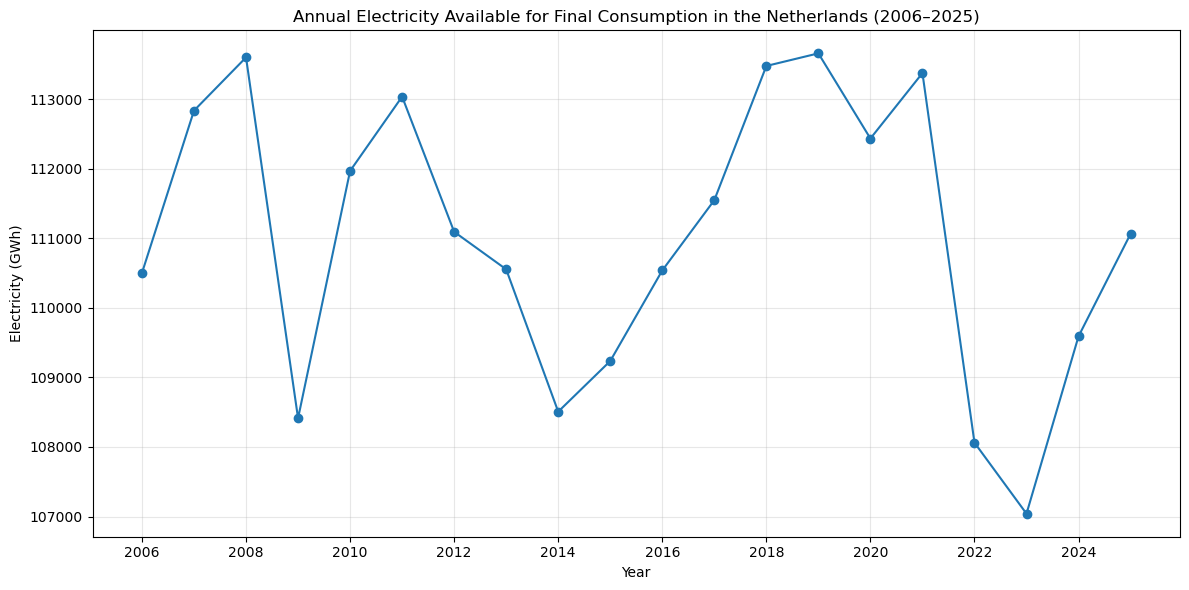

In [14]:
# Plot annual electricity available for final consumption
plt.figure(figsize=(12, 6))

plt.plot(
    eurostat_annual["Year"],
    eurostat_annual["Electricity_GWh"],
    marker="o"
)

plt.title("Annual Electricity Available for Final Consumption in the Netherlands (2006–2025)")
plt.xlabel("Year")
plt.ylabel("Electricity (GWh)")

# Show whole years at two-year intervals
plt.xticks(range(2006, 2026, 2))

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# Calculate the year-to-year change in electricity available for final consumption
eurostat_annual["Change_GWh"] = (
    eurostat_annual["Electricity_GWh"].diff()
)

eurostat_annual["Change_Percent"] = (
    eurostat_annual["Electricity_GWh"].pct_change() * 100
)

# Display the annual values and their changes
display(
    eurostat_annual[
        ["Year", "Electricity_GWh", "Change_GWh", "Change_Percent"]
    ].round(2)
)

,Year,Electricity_GWh,Change_GWh,Change_Percent
0,2006,110501.00,NaN,NaN
1,2007,112835.00,2334.00,2.11
2,2008,113600.00,765.00,0.68
3,2009,108413.00,-5187.00,-4.57
4,2010,111968.00,3555.00,3.28
5,2011,113036.00,1068.00,0.95
6,2012,111093.14,-1942.86,-1.72
7,2013,110553.79,-539.35,-0.49
8,2014,108507.70,-2046.09,-1.85
9,2015,109235.61,727.92,0.67


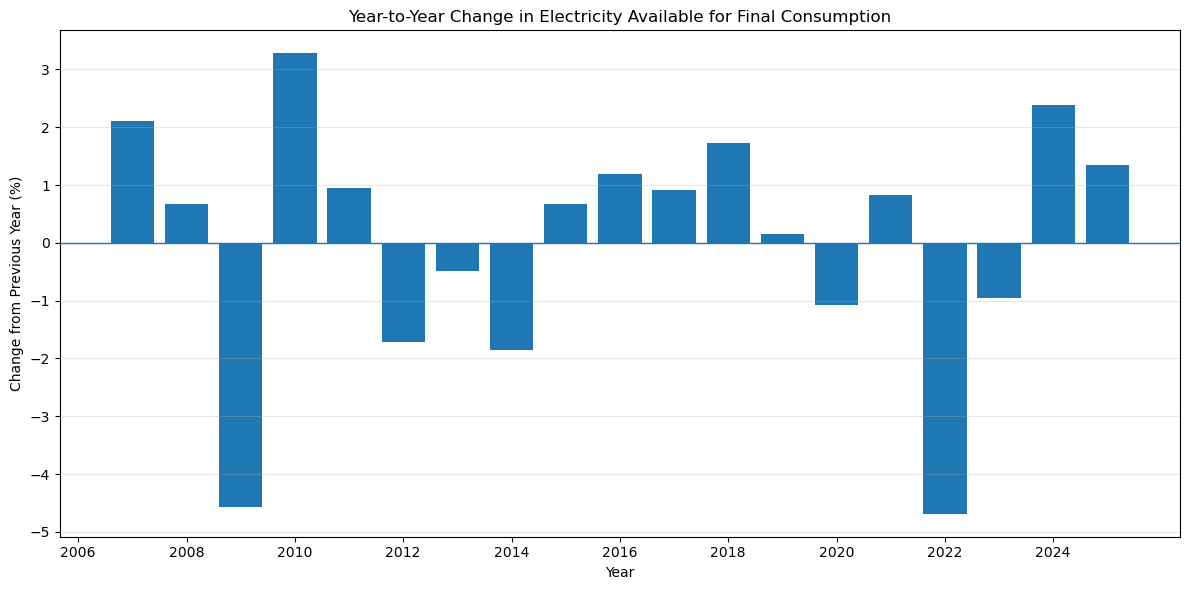

In [16]:
# Plot year-to-year percentage changes in electricity availability
plt.figure(figsize=(12, 6))

plt.bar(
    eurostat_annual["Year"],
    eurostat_annual["Change_Percent"]
)

plt.axhline(0, linewidth=1)
plt.title("Year-to-Year Change in Electricity Available for Final Consumption")
plt.xlabel("Year")
plt.ylabel("Change from Previous Year (%)")
plt.xticks(range(2006, 2026, 2))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ENTSO-E — Historical Hourly Electricity Demand

## Data Investigation, Cleaning and Preparation (2006–2025)

This section investigates historical hourly electricity demand in the Netherlands using multiple ENTSO-E data files covering different periods.

Each dataset will be inspected and cleaned separately because the file structures, timestamp formats and data-quality issues may differ. Once the individual segments have been investigated and standardized, they will be combined into a consistent historical time series for further analysis.

In [17]:
# Load the 2006–2015 ENTSO-E workbook and inspect its sheets
entsoe_2006_2015_file = "../data/raw/Monthly-hourly-load-values_2006-2015.xlsx"

entsoe_excel = pd.ExcelFile(entsoe_2006_2015_file)

print("Available sheets:", entsoe_excel.sheet_names)

Available sheets: ['MHLV_2006-2015']


In [18]:
# Read the 2006–2015 worksheet and inspect its first rows
entsoe_2006_2015_raw = pd.read_excel(
    entsoe_2006_2015_file,
    sheet_name="MHLV_2006-2015"
)

display(entsoe_2006_2015_raw.head())
print("Dataset shape:", entsoe_2006_2015_raw.shape)
print("Column names:", entsoe_2006_2015_raw.columns.tolist())

,Hourly load values 2006-2015,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26,Unnamed: 27,Unnamed: 28
0,Values in MW,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"To get the real value, you need to scale them ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Country,Year,Month,Day,Coverage ratio,0.0,1.0,2.0,3.0,4.0,...,14.0,15.0,16.0,17.0,18.0,19.0,20.0,21.0,22.0,23.0
3,AT,2006,1,1,100,6297.0,6005.0,5743.0,5397.0,5213.0,...,6247.0,6231.0,6603.0,6979.0,7022.0,6930.0,6560.0,6170.0,6501.0,6168.0
4,AT,2006,1,2,100,5900.0,5643.0,5524.0,5372.0,5481.0,...,8190.0,8168.0,8469.0,8735.0,8617.0,8218.0,7773.0,7247.0,7413.0,6926.0


Dataset shape: (116805, 29)
Column names: ['Hourly load values 2006-2015', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', 'Unnamed: 27', 'Unnamed: 28']


In [19]:
# Load the workbook with the correct headers and standardize column names
entsoe_2006_2015_raw = pd.read_excel(
    entsoe_2006_2015_file,
    sheet_name="MHLV_2006-2015",
    header=2
)

entsoe_2006_2015_raw.columns = [
    "Country", "Year", "Month", "Day", "Coverage_ratio"
] + list(range(24))

print("Dataset shape:", entsoe_2006_2015_raw.shape)
display(entsoe_2006_2015_raw.head())

Dataset shape: (116803, 29)


,Country,Year,Month,Day,Coverage_ratio,0,1,2,3,4,...,14,15,16,17,18,19,20,21,22,23
0,Country,Year,Month,Day,Coverage ratio,0.0,1.0,2.0,3.0,4.0,...,14.0,15.0,16.0,17.0,18.0,19.0,20.0,21.0,22.0,23.0
1,AT,2006,1,1,100,6297.0,6005.0,5743.0,5397.0,5213.0,...,6247.0,6231.0,6603.0,6979.0,7022.0,6930.0,6560.0,6170.0,6501.0,6168.0
2,AT,2006,1,2,100,5900.0,5643.0,5524.0,5372.0,5481.0,...,8190.0,8168.0,8469.0,8735.0,8617.0,8218.0,7773.0,7247.0,7413.0,6926.0
3,AT,2006,1,3,100,6483.0,6192.0,5991.0,5773.0,5849.0,...,8112.0,8055.0,8342.0,8670.0,8534.0,8203.0,7745.0,7214.0,7397.0,6981.0
4,AT,2006,1,4,100,6522.0,6217.0,6027.0,5802.0,5866.0,...,8145.0,8081.0,8331.0,8470.0,8460.0,8185.0,7759.0,7242.0,7441.0,6981.0


In [20]:
# Check column names, data types, and missing values before cleaning
print(entsoe_2006_2015_raw.dtypes)
print("\nMissing values per column:")
display(entsoe_2006_2015_raw.isna().sum())

Country            object
Year               object
Month              object
Day                object
Coverage_ratio     object
0                 float64
1                 float64
2                 float64
3                 float64
4                 float64
5                 float64
6                 float64
7                 float64
8                 float64
9                 float64
10                float64
11                float64
12                float64
13                float64
14                float64
15                float64
16                float64
17                float64
18                float64
19                float64
20                float64
21                float64
22                float64
23                float64
dtype: object

Missing values per column:


Country              0
Year                 0
Month                0
Day                  0
Coverage_ratio    1889
0                    9
1                   11
2                  321
3                   14
4                   12
5                   12
6                   11
7                   10
8                   10
9                   10
10                  10
11                  11
12                  10
13                  10
14                  10
15                  11
16                  10
17                  10
18                  10
19                  10
20                  10
21                  10
22                  10
23                  21
dtype: int64

In [21]:
# Remove the repeated column-header row that was imported as data
entsoe_2006_2015_raw = entsoe_2006_2015_raw[
    entsoe_2006_2015_raw["Country"] != "Country"
].copy()

# Keep only records for the Netherlands
entsoe_nl_2006_2015 = entsoe_2006_2015_raw[
    entsoe_2006_2015_raw["Country"] == "NL"
].copy()

print("Netherlands records:", len(entsoe_nl_2006_2015))
print("Years covered:", sorted(entsoe_nl_2006_2015["Year"].astype(int).unique()))

Netherlands records: 3652
Years covered: [np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015)]


In [22]:
# Check date coverage, hourly columns, and daily coverage ratios
hourly_columns = list(range(24))

# Build dates from the existing Year, Month, and Day columns
dates = pd.to_datetime(
    entsoe_nl_2006_2015[["Year", "Month", "Day"]]
)

print("Date range:", dates.min(), "to", dates.max())

print("\nHourly columns present:",
      [col for col in hourly_columns
       if col in entsoe_nl_2006_2015.columns])

print("\nCoverage ratio summary:")
display(entsoe_nl_2006_2015["Coverage_ratio"].describe())

print("\nRows with incomplete coverage:",
      (entsoe_nl_2006_2015["Coverage_ratio"] < 100).sum())


Date range: 2006-01-01 00:00:00 to 2015-12-31 00:00:00

Hourly columns present: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]

Coverage ratio summary:


count     3652
unique       1
top        100
freq      3652
Name: Coverage_ratio, dtype: int64


Rows with incomplete coverage: 0


In [23]:
# Check missing values in the 24 hourly demand columns for the Netherlands
hourly_columns = list(range(24))

missing_hourly_values = entsoe_nl_2006_2015[hourly_columns].isna().sum()

print("Total missing hourly values:", missing_hourly_values.sum())
print("\nMissing values per hour:")
display(missing_hourly_values)

Total missing hourly values: 10

Missing values per hour:


0      0
1      0
2     10
3      0
4      0
5      0
6      0
7      0
8      0
9      0
10     0
11     0
12     0
13     0
14     0
15     0
16     0
17     0
18     0
19     0
20     0
21     0
22     0
23     0
dtype: int64

In [24]:
# Identify the dates with missing demand readings at hour 2
missing_dates = entsoe_nl_2006_2015.loc[
    entsoe_nl_2006_2015[2].isna(),
    ["Year", "Month", "Day", "Coverage_ratio"]
].copy()

display(missing_dates)
print("Number of affected dates:", len(missing_dates))

,Year,Month,Day,Coverage_ratio
83654,2006,3,26,100
84018,2007,3,25,100
84389,2008,3,30,100
84753,2009,3,29,100
85117,2010,3,28,100
85481,2011,3,27,100
85845,2012,3,25,100
86216,2013,3,31,100
86580,2014,3,30,100
86944,2015,3,29,100


Number of affected dates: 10


### Finding: Missing Hourly Readings Due to Daylight Saving Time

The dataset contains 10 missing hourly readings, all at hour `2`, occurring on the last Sunday of March in each year from 2006 to 2015. This pattern is consistent with the transition to daylight saving time, when the clock moves forward and the 02:00 hour is skipped.

**Decision:** These missing readings are treated as an expected time-related gap rather than ordinary missing data. We will account for the daylight-saving-time transition when preparing the hourly time series, rather than automatically imputing these values.

In [25]:
# Reshape daily records into one row per date and hour
entsoe_nl_2006_2015_hourly = entsoe_nl_2006_2015.melt(
    id_vars=["Country", "Year", "Month", "Day", "Coverage_ratio"],
    value_vars=list(range(24)),
    var_name="Hour",
    value_name="Demand_MW"
)

display(entsoe_nl_2006_2015_hourly.head())
print("Hourly dataset shape:", entsoe_nl_2006_2015_hourly.shape)

,Country,Year,Month,Day,Coverage_ratio,Hour,Demand_MW
0,NL,2006,1,1,100,0,10215.0
1,NL,2006,1,2,100,0,9590.0
2,NL,2006,1,3,100,0,11064.0
3,NL,2006,1,4,100,0,11088.0
4,NL,2006,1,5,100,0,10925.0


Hourly dataset shape: (87648, 7)


In [26]:
# Create a timestamp for each date and hour in the reshaped dataset
entsoe_nl_2006_2015_hourly["Timestamp"] = (
    pd.to_datetime(
        entsoe_nl_2006_2015_hourly[["Year", "Month", "Day"]]
    )
    + pd.to_timedelta(entsoe_nl_2006_2015_hourly["Hour"], unit="h")
)

# Arrange records chronologically
entsoe_nl_2006_2015_hourly = (
    entsoe_nl_2006_2015_hourly
    .sort_values("Timestamp")
    .reset_index(drop=True)
)

display(
    entsoe_nl_2006_2015_hourly[
        ["Timestamp", "Demand_MW", "Coverage_ratio"]
    ].head()
)

,Timestamp,Demand_MW,Coverage_ratio
0,2006-01-01 00:00:00,10215.0,100
1,2006-01-01 01:00:00,9979.0,100
2,2006-01-01 02:00:00,9460.0,100
3,2006-01-01 03:00:00,8833.0,100
4,2006-01-01 04:00:00,8525.0,100


In [27]:
# Check timestamp uniqueness and missing demand values after reshaping
print("Duplicate timestamps:",
      entsoe_nl_2006_2015_hourly["Timestamp"].duplicated().sum())

print("Missing demand values:",
      entsoe_nl_2006_2015_hourly["Demand_MW"].isna().sum())

print("Total hourly records:",
      len(entsoe_nl_2006_2015_hourly))

# Inspect demand readings around the 2006 spring clock change
display(
    entsoe_nl_2006_2015_hourly.loc[
        entsoe_nl_2006_2015_hourly["Timestamp"].between(
            "2006-03-26 00:00",
            "2006-03-26 05:00"
        ),
        ["Timestamp", "Hour", "Demand_MW"]
    ]
)

Duplicate timestamps: 0
Missing demand values: 10
Total hourly records: 87648


,Timestamp,Hour,Demand_MW
2016,2006-03-26 00:00:00,0,10287.0
2017,2006-03-26 01:00:00,1,9549.0
2018,2006-03-26 02:00:00,2,NaN
2019,2006-03-26 03:00:00,3,9039.0
2020,2006-03-26 04:00:00,4,8787.0
2021,2006-03-26 05:00:00,5,8726.0


### Data Quality Decision: Missing Hourly Demand Values

In [28]:
# Check total records and missing demand values by year
for year, group in entsoe_nl_2006_2015_hourly.groupby("Year"):
    print(
        int(year),
        "records:", len(group),
        "| missing demand:", group["Demand_MW"].isna().sum()
    )

2006 records: 8760 | missing demand: 1
2007 records: 8760 | missing demand: 1
2008 records: 8784 | missing demand: 1
2009 records: 8760 | missing demand: 1
2010 records: 8760 | missing demand: 1
2011 records: 8760 | missing demand: 1
2012 records: 8784 | missing demand: 1
2013 records: 8760 | missing demand: 1
2014 records: 8760 | missing demand: 1
2015 records: 8760 | missing demand: 1


In [29]:
# Check data types and identify any non-numeric hourly demand values
print("Demand data type:", entsoe_nl_2006_2015_hourly["Demand_MW"].dtype)

non_numeric_demand = pd.to_numeric(
    entsoe_nl_2006_2015_hourly["Demand_MW"],
    errors="coerce"
).isna().sum()

print("Missing or non-numeric demand values:", non_numeric_demand)

Demand data type: float64
Missing or non-numeric demand values: 10


### Data Quality Decision: Missing Hourly Demand

The 2006–2015 dataset contains 10 missing demand readings at 02:00 on the last Sunday of March, one per year. This pattern is consistent with the spring daylight-saving-time transition.

The original workbook does not document its timezone convention. The later datasets use a `DateUTC` column, so the timestamp conventions cannot yet be confirmed as equivalent.

**Decision:** The 10 missing values will not be imputed by copying the 03:00 reading. They will be retained temporarily while the datasets are prepared. The timezone limitation will be documented, and the affected records will be handled explicitly during final assembly.

The two suspicious zero readings identified in March and April 2006 have been imputed separately using nearby same-hour medians.

In [30]:
# Inspect hourly records with zero or unusually low demand
low_demand_records = entsoe_nl_2006_2015_hourly[
    entsoe_nl_2006_2015_hourly["Demand_MW"] <= 1000
][["Timestamp", "Demand_MW"]]

display(low_demand_records)
print("Number of records with demand <= 1,000 MW:", len(low_demand_records))

,Timestamp,Demand_MW
1416,2006-03-01,0.0
2160,2006-04-01,0.0


Number of records with demand <= 1,000 MW: 2


### Data Quality Decision: Two Zero-Demand Readings

During the inspection of the original ENTSO-E workbook, two zero-demand readings were identified for the Netherlands:

- 1 March 2006 at 00:00
- 1 April 2006 at 00:00

Both readings were surrounded by plausible electricity-demand values, suggesting that the zeros may be data-quality anomalies.

**Decision:** The two zero values were replaced with estimated values using the median demand at the same hour from the surrounding seven-day period before and after each timestamp.

This approach preserves both timestamps and the expected hourly structure of the dataset while avoiding the use of zero as a demand value. The imputed values are estimates, not observed measurements, and this limitation should be considered when interpreting the historical data.

The original source workbook remains unchanged.

In [31]:
# Replace the two suspicious zero readings using nearby same-hour medians
invalid_timestamps = pd.to_datetime([
    "2006-03-01 00:00:00",
    "2006-04-01 00:00:00"
])

for timestamp in invalid_timestamps:
    nearby_same_hour = entsoe_nl_2006_2015_hourly.loc[
        (
            entsoe_nl_2006_2015_hourly["Timestamp"]
            .between(
                timestamp - pd.Timedelta(days=7),
                timestamp + pd.Timedelta(days=7)
            )
        )
        & (
            entsoe_nl_2006_2015_hourly["Timestamp"].dt.hour
            == timestamp.hour
        )
        & entsoe_nl_2006_2015_hourly["Demand_MW"].gt(0),
        "Demand_MW"
    ]

    estimated_demand = nearby_same_hour.median()

    entsoe_nl_2006_2015_hourly.loc[
        entsoe_nl_2006_2015_hourly["Timestamp"] == timestamp,
        "Demand_MW"
    ] = estimated_demand

    print(f"{timestamp}: estimated demand = {estimated_demand:.1f} MW")


2006-03-01 00:00:00: estimated demand = 10518.5 MW
2006-04-01 00:00:00: estimated demand = 10910.5 MW


In [32]:
# Summarize hourly electricity demand by year
annual_demand_summary = (
    entsoe_nl_2006_2015_hourly
    .groupby("Year")["Demand_MW"]
    .agg(["mean", "min", "max"])
    .reset_index()
    .rename(columns={
        "mean": "Average_Demand_MW",
        "min": "Minimum_Demand_MW",
        "max": "Maximum_Demand_MW"
    })
)

display(annual_demand_summary.round(2))

,Year,Average_Demand_MW,Minimum_Demand_MW,Maximum_Demand_MW
0,2006,12602.59,7561.0,17855.0
1,2007,12504.85,7723.0,18234.0
2,2008,13014.22,5767.0,18465.0
3,2009,12105.70,7206.0,17840.0
4,2010,12618.58,8112.0,18390.0
5,2011,12652.89,8167.0,18049.0
6,2012,12267.64,7825.0,17734.0
7,2013,13008.80,8257.0,18457.0
8,2014,12706.79,8136.0,18460.0
9,2015,12928.48,8892.0,17761.0


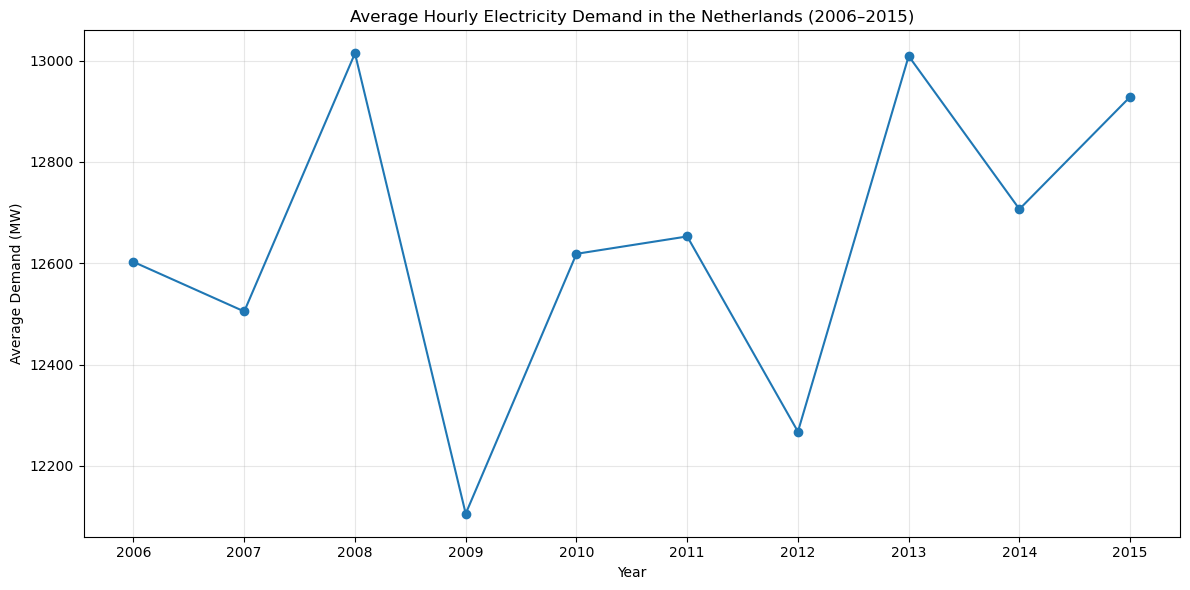

In [33]:
# Plot the average hourly electricity demand for each year from 2006 to 2015
plt.figure(figsize=(12, 6))
plt.plot(
    annual_demand_summary["Year"],
    annual_demand_summary["Average_Demand_MW"],
    marker="o"
)

plt.title("Average Hourly Electricity Demand in the Netherlands (2006–2015)")
plt.xlabel("Year")
plt.ylabel("Average Demand (MW)")
plt.xticks(annual_demand_summary["Year"].astype(int))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:
# Verify annual record counts and missing demand values after cleaning
annual_record_check = (
    entsoe_nl_2006_2015_hourly
    .groupby("Year")
    .agg(
        Hourly_Records=("Timestamp", "size"),
        Missing_Demand=("Demand_MW", lambda x: x.isna().sum())
    )
    .reset_index()
)

display(annual_record_check)

,Year,Hourly_Records,Missing_Demand
0,2006,8760,1
1,2007,8760,1
2,2008,8784,1
3,2009,8760,1
4,2010,8760,1
5,2011,8760,1
6,2012,8784,1
7,2013,8760,1
8,2014,8760,1
9,2015,8760,1


## ENTSO-E Historical Dataset: 2015–2019

In this section, we import and inspect the next ENTSO-E historical electricity demand dataset covering 2015–2019. We will examine its worksheet structure and data format before proceeding with cleaning and preparation.

In [35]:
# Load the 2015–2019 ENTSO-E Excel workbook
entsoe_2015_2019_file = "../data/raw/MHLV_data-2015-2019.xlsx"

entsoe_2015_2019_excel = pd.ExcelFile(entsoe_2015_2019_file)

print("Available sheets:", entsoe_2015_2019_excel.sheet_names)

Available sheets: ['2015-2017', '2018-2019']


In [36]:
# Inspect the first worksheet to understand its structure and column names
entsoe_2015_2019_raw = pd.read_excel(
    entsoe_2015_2019_file,
    sheet_name=entsoe_2015_2019_excel.sheet_names[0]
)

display(entsoe_2015_2019_raw.head())
print("Dataset shape:", entsoe_2015_2019_raw.shape)
print("Column names:", entsoe_2015_2019_raw.columns.tolist())

,MeasureItem,DateUTC,DateShort,TimeFrom,TimeTo,CountryCode,Cov_ratio,Value,Value_ScaleTo100
0,Monthly Hourly Load Values,2014-12-31 23:00:00,2014-12-31,23:00:00,00:00:00,DE,98,46419.79,47367.132653
1,Monthly Hourly Load Values,2015-01-01 00:00:00,2015-01-01,00:00:00,01:00:00,DE,98,44898.30,45814.591837
2,Monthly Hourly Load Values,2015-01-01 01:00:00,2015-01-01,01:00:00,02:00:00,DE,98,43305.31,44189.091837
3,Monthly Hourly Load Values,2015-01-01 02:00:00,2015-01-01,02:00:00,03:00:00,DE,98,41918.17,42773.642857
4,Monthly Hourly Load Values,2015-01-01 03:00:00,2015-01-01,03:00:00,04:00:00,DE,98,41330.17,42173.642857


Dataset shape: (631600, 9)
Column names: ['MeasureItem', 'DateUTC', 'DateShort', 'TimeFrom', 'TimeTo', 'CountryCode', 'Cov_ratio', 'Value', 'Value_ScaleTo100']


In [37]:
# Check which countries and years are available in the dataset
print("Countries available:")
display(entsoe_2015_2019_raw["CountryCode"].value_counts())

print("\nDate range:")
print(entsoe_2015_2019_raw["DateUTC"].min(),
      "to",
      entsoe_2015_2019_raw["DateUTC"].max())

print("\nMissing values per column:")
display(entsoe_2015_2019_raw.isna().sum())

Countries available:


CountryCode
DE    26305
EE    17546
FI    17546
GR    17546
LT    17546
LV    17546
RO    17546
TR    17546
BG    17546
NO    17545
ME    17545
MK    17545
NL    17545
SI    17545
PL    17545
RS    17545
SE    17545
IT    17545
SK    17545
LU    17545
HR    17545
HU    17545
FR    17545
ES    17545
DK    17545
CZ    17545
CY    17545
CH    17545
BE    17545
BA    17545
AT    17545
GB    17544
IE    17544
IS    17544
PT    17544
AL     8761
Name: count, dtype: int64


Date range:
2014-12-31 23:00:00 to 2017-12-31 23:00:00

Missing values per column:


MeasureItem         0
DateUTC             0
DateShort           0
TimeFrom            0
TimeTo              0
CountryCode         0
Cov_ratio           0
Value               0
Value_ScaleTo100    0
dtype: int64

In [38]:
# Filter the historical dataset to retain Dutch electricity demand records
entsoe_nl_2015_2019 = entsoe_2015_2019_raw[
    entsoe_2015_2019_raw["CountryCode"] == "NL"
].copy()

print("Netherlands dataset shape:", entsoe_nl_2015_2019.shape)
print("Date range:",
      entsoe_nl_2015_2019["DateUTC"].min(),
      "to",
      entsoe_nl_2015_2019["DateUTC"].max())
print("Duplicate timestamps:",
      entsoe_nl_2015_2019["DateUTC"].duplicated().sum())

display(entsoe_nl_2015_2019.head())

Netherlands dataset shape: (17545, 9)
Date range: 2015-12-31 23:00:00 to 2017-12-31 23:00:00
Duplicate timestamps: 0


,MeasureItem,DateUTC,DateShort,TimeFrom,TimeTo,CountryCode,Cov_ratio,Value,Value_ScaleTo100
8790,Monthly Hourly Load Values,2015-12-31 23:00:00,2015-12-31,23:00:00,00:00:00,NL,100,11373.0,11373.0
8824,Monthly Hourly Load Values,2016-01-01 00:00:00,2016-01-01,00:00:00,01:00:00,NL,100,11102.0,11102.0
8859,Monthly Hourly Load Values,2016-01-01 01:00:00,2016-01-01,01:00:00,02:00:00,NL,100,10657.0,10657.0
8894,Monthly Hourly Load Values,2016-01-01 02:00:00,2016-01-01,02:00:00,03:00:00,NL,100,10238.0,10238.0
8929,Monthly Hourly Load Values,2016-01-01 03:00:00,2016-01-01,03:00:00,04:00:00,NL,100,10018.0,10018.0


In [39]:
# Check coverage ratios and demand-value quality for the Netherlands
print("Coverage ratio distribution:")
display(entsoe_nl_2015_2019["Cov_ratio"].value_counts().sort_index())

print("\nMissing values:")
display(
    entsoe_nl_2015_2019[
        ["DateUTC", "Cov_ratio", "Value", "Value_ScaleTo100"]
    ].isna().sum()
)

print("\nDemand value summary:")
display(
    entsoe_nl_2015_2019[["Value", "Value_ScaleTo100"]].describe().round(2)
)

Coverage ratio distribution:


Cov_ratio
100    17545
Name: count, dtype: int64


Missing values:


DateUTC             0
Cov_ratio           0
Value               0
Value_ScaleTo100    0
dtype: int64


Demand value summary:


,Value,Value_ScaleTo100
count,17545.00,17545.00
mean,13084.20,13084.20
std,2079.02,2079.02
min,7490.00,7490.00
25%,11281.00,11281.00
50%,13042.00,13042.00
75%,14671.00,14671.00
max,18620.00,18620.00


In [40]:
# Select and standardize the timestamp and demand columns for the Netherlands
entsoe_nl_2015_2017_clean = (
    entsoe_nl_2015_2019[
        ["DateUTC", "Value"]
    ]
    .rename(columns={
        "DateUTC": "Timestamp",
        "Value": "Demand_MW"
    })
    .copy()
    .sort_values("Timestamp")
    .reset_index(drop=True)
)

print("Dataset shape:", entsoe_nl_2015_2017_clean.shape)
print("Date range:",
      entsoe_nl_2015_2017_clean["Timestamp"].min(),
      "to",
      entsoe_nl_2015_2017_clean["Timestamp"].max())
print("Duplicate timestamps:",
      entsoe_nl_2015_2017_clean["Timestamp"].duplicated().sum())

display(entsoe_nl_2015_2017_clean.head())

Dataset shape: (17545, 2)
Date range: 2015-12-31 23:00:00 to 2017-12-31 23:00:00
Duplicate timestamps: 0


,Timestamp,Demand_MW
0,2015-12-31 23:00:00,11373.0
1,2016-01-01 00:00:00,11102.0
2,2016-01-01 01:00:00,10657.0
3,2016-01-01 02:00:00,10238.0
4,2016-01-01 03:00:00,10018.0


In [41]:
# Check whether consecutive timestamps are exactly one hour apart
time_gaps = entsoe_nl_2015_2017_clean["Timestamp"].diff()

print("Time gaps other than one hour:", (time_gaps.dropna() != pd.Timedelta(hours=1)).sum())
display(
    entsoe_nl_2015_2017_clean.loc[
        time_gaps.notna() & (time_gaps != pd.Timedelta(hours=1)),
        ["Timestamp", "Demand_MW"]
    ].assign(
        Previous_Timestamp=lambda df: df["Timestamp"].shift(1)
    )
)

Time gaps other than one hour: 0


,Timestamp,Demand_MW,Previous_Timestamp


## Inspecting the 2018-2019 sheet

In [42]:
# Load and inspect the 2018–2019 historical worksheet
entsoe_2018_2019_file = "../data/raw/MHLV_data-2015-2019.xlsx"

entsoe_2018_2019_raw = pd.read_excel(
    entsoe_2018_2019_file,
    sheet_name="2018-2019"
)

print("Shape:", entsoe_2018_2019_raw.shape)
print("Columns:", entsoe_2018_2019_raw.columns.tolist())

display(entsoe_2018_2019_raw.head())
display(entsoe_2018_2019_raw.tail())


Shape: (476960, 9)
Columns: ['MeasureItem', 'DateUTC', 'DateShort', 'TimeFrom', 'TimeTo', 'CountryCode', 'Cov_ratio', 'Value', 'Value_ScaleTo100']


,MeasureItem,DateUTC,DateShort,TimeFrom,TimeTo,CountryCode,Cov_ratio,Value,Value_ScaleTo100
0,Monthly Hourly Load Values,2018-01-01,2018-01-01,00:00:00,01:00:00,AL,100,746.45,746.45
1,Monthly Hourly Load Values,2018-01-01,2018-01-01,00:00:00,01:00:00,AT,100,6414.00,6414.00
2,Monthly Hourly Load Values,2018-01-01,2018-01-01,00:00:00,01:00:00,BA,100,1249.00,1249.00
3,Monthly Hourly Load Values,2018-01-01,2018-01-01,00:00:00,01:00:00,BE,100,8379.00,8379.00
4,Monthly Hourly Load Values,2018-01-01,2018-01-01,00:00:00,01:00:00,BG,100,3424.49,3424.49


,MeasureItem,DateUTC,DateShort,TimeFrom,TimeTo,CountryCode,Cov_ratio,Value,Value_ScaleTo100
476955,Monthly Hourly Load Values,2019-10-31 22:00:00,2019-10-31,22:00:00,23:00:00,HR,100,1767.00,1767.00
476956,Monthly Hourly Load Values,2019-10-31 22:00:00,2019-10-31,22:00:00,23:00:00,HU,100,4804.89,4804.89
476957,Monthly Hourly Load Values,2019-10-31 22:00:00,2019-10-31,22:00:00,23:00:00,MK,100,872.00,872.00
476958,Monthly Hourly Load Values,2019-10-31 22:00:00,2019-10-31,22:00:00,23:00:00,PT,100,5921.00,5921.00
476959,Monthly Hourly Load Values,2019-10-31 23:00:00,2019-10-31,23:00:00,00:00:00,PT,100,5460.00,5460.00


In [43]:
# Filter the 2018–2019 worksheet for the Netherlands and inspect data quality
entsoe_nl_2018_2019 = entsoe_2018_2019_raw.loc[
    entsoe_2018_2019_raw["CountryCode"] == "NL"
].copy()

entsoe_nl_2018_2019["DateUTC"] = pd.to_datetime(
    entsoe_nl_2018_2019["DateUTC"]
)

print("Shape:", entsoe_nl_2018_2019.shape)
print(
    "Date range:",
    entsoe_nl_2018_2019["DateUTC"].min(),
    "to",
    entsoe_nl_2018_2019["DateUTC"].max()
)
print(
    "Duplicate timestamps:",
    entsoe_nl_2018_2019["DateUTC"].duplicated().sum()
)
print(
    "Missing demand values:",
    entsoe_nl_2018_2019["Value"].isna().sum()
)
print(
    "Coverage ratios:",
    entsoe_nl_2018_2019["Cov_ratio"].value_counts(dropna=False).to_dict()
)
print(
    "Differences between Value and Value_ScaleTo100:",
    (
        entsoe_nl_2018_2019["Value"]
        != entsoe_nl_2018_2019["Value_ScaleTo100"]
    ).sum()
)

display(
    entsoe_nl_2018_2019[
        ["DateUTC", "TimeFrom", "TimeTo", "Cov_ratio", "Value"]
    ].head()
)
display(
    entsoe_nl_2018_2019[
        ["DateUTC", "TimeFrom", "TimeTo", "Cov_ratio", "Value"]
    ].tail()
)


Shape: (11638, 9)
Date range: 2018-01-01 00:00:00 to 2019-04-30 21:00:00
Duplicate timestamps: 0
Missing demand values: 0
Coverage ratios: {100: 11638}
Differences between Value and Value_ScaleTo100: 0


,DateUTC,TimeFrom,TimeTo,Cov_ratio,Value
26,2018-01-01 00:00:00,00:00:00,01:00:00,100,11255.0
62,2018-01-01 01:00:00,01:00:00,02:00:00,100,10956.0
98,2018-01-01 02:00:00,02:00:00,03:00:00,100,10647.0
134,2018-01-01 03:00:00,03:00:00,04:00:00,100,10431.0
170,2018-01-01 04:00:00,04:00:00,05:00:00,100,10431.0


,DateUTC,TimeFrom,TimeTo,Cov_ratio,Value
398430,2019-04-30 17:00:00,17:00:00,18:00:00,100,13910.0
398458,2019-04-30 18:00:00,18:00:00,19:00:00,100,13773.0
398486,2019-04-30 19:00:00,19:00:00,20:00:00,100,13652.0
398514,2019-04-30 20:00:00,20:00:00,21:00:00,100,13048.0
398542,2019-04-30 21:00:00,21:00:00,22:00:00,100,12408.0


### Create the clean 2018 dataset

In [44]:
# Standardise the historical data and retain only the complete 2018 calendar year
entsoe_nl_2018_clean = (
    entsoe_nl_2018_2019.loc[
        entsoe_nl_2018_2019["DateUTC"].dt.year == 2018,
        ["DateUTC", "Value"]
    ]
    .rename(columns={
        "DateUTC": "Timestamp",
        "Value": "Demand_MW"
    })
    .copy()
    .sort_values("Timestamp")
    .reset_index(drop=True)
)

print("Shape:", entsoe_nl_2018_clean.shape)
print(
    "Date range:",
    entsoe_nl_2018_clean["Timestamp"].min(),
    "to",
    entsoe_nl_2018_clean["Timestamp"].max()
)
print(
    "Duplicate timestamps:",
    entsoe_nl_2018_clean["Timestamp"].duplicated().sum()
)
print(
    "Non-hourly gaps:",
    (
        entsoe_nl_2018_clean["Timestamp"].diff().dropna()
        != pd.Timedelta(hours=1)
    ).sum()
)

display(entsoe_nl_2018_clean.head())
display(entsoe_nl_2018_clean.tail())


Shape: (8760, 2)
Date range: 2018-01-01 00:00:00 to 2018-12-31 23:00:00
Duplicate timestamps: 0
Non-hourly gaps: 0


,Timestamp,Demand_MW
0,2018-01-01 00:00:00,11255.0
1,2018-01-01 01:00:00,10956.0
2,2018-01-01 02:00:00,10647.0
3,2018-01-01 03:00:00,10431.0
4,2018-01-01 04:00:00,10431.0


,Timestamp,Demand_MW
8755,2018-12-31 19:00:00,13117.0
8756,2018-12-31 20:00:00,12369.0
8757,2018-12-31 21:00:00,11937.0
8758,2018-12-31 22:00:00,11710.0
8759,2018-12-31 23:00:00,11557.0


In [45]:
# Check the historical transition from 2017 to 2018
print("End of 2015–2017 dataset:")
display(
    entsoe_nl_2015_2017_clean.tail(5)
)

print("Start of 2018 dataset:")
display(
    entsoe_nl_2018_clean.head(5)
)

print(
    "Time difference between boundary records:",
    entsoe_nl_2018_clean["Timestamp"].iloc[0]
    - entsoe_nl_2015_2017_clean["Timestamp"].iloc[-1]
)


End of 2015–2017 dataset:


,Timestamp,Demand_MW
17540,2017-12-31 19:00:00,12139.0
17541,2017-12-31 20:00:00,11207.0
17542,2017-12-31 21:00:00,11175.0
17543,2017-12-31 22:00:00,13121.0
17544,2017-12-31 23:00:00,11375.0


Start of 2018 dataset:


,Timestamp,Demand_MW
0,2018-01-01 00:00:00,11255.0
1,2018-01-01 01:00:00,10956.0
2,2018-01-01 02:00:00,10647.0
3,2018-01-01 03:00:00,10431.0
4,2018-01-01 04:00:00,10431.0


Time difference between boundary records: 0 days 01:00:00


## ENTSO-E Historical Dataset: 2019

In this section, we load and validate the 2019 annual ENTSO-E CSV file. We filter for the Netherlands, inspect data quality, and standardise the hourly records for later combination with the historical datasets.

In [46]:
# Load and inspect the first annual ENTSO-E CSV file
entsoe_2019_file = "../data/raw/monthly_hourly_load_values_2019.csv"

entsoe_2019_raw = pd.read_csv(entsoe_2019_file)

print("Shape:", entsoe_2019_raw.shape)
print("Columns:", entsoe_2019_raw.columns.tolist())
display(entsoe_2019_raw.head())
display(entsoe_2019_raw.tail())


Shape: (295357, 11)
Columns: ['MeasureItem', 'DateUTC', 'DateShort', 'TimeFrom', 'TimeTo', 'CountryCode', 'Cov_ratio', 'Value', 'Value_ScaleTo100', 'CreateDate', 'UpdateDate']


,MeasureItem,DateUTC,DateShort,TimeFrom,TimeTo,CountryCode,Cov_ratio,Value,Value_ScaleTo100,CreateDate,UpdateDate
0,Monthly Hourly Load Values,01-01-2019 00:00,01-01-2019,00:00,01:00,AT,100,5852.5,5852.5,29-05-2024 11:37:27,29-05-2024 11:37:27
1,Monthly Hourly Load Values,01-01-2019 01:00,01-01-2019,01:00,02:00,AT,100,5619.2,5619.2,29-05-2024 11:37:27,29-05-2024 11:37:27
2,Monthly Hourly Load Values,01-01-2019 02:00,01-01-2019,02:00,03:00,AT,100,5323.9,5323.9,29-05-2024 11:37:27,29-05-2024 11:37:27
3,Monthly Hourly Load Values,01-01-2019 03:00,01-01-2019,03:00,04:00,AT,100,5273.3,5273.3,29-05-2024 11:37:27,29-05-2024 11:37:27
4,Monthly Hourly Load Values,01-01-2019 04:00,01-01-2019,04:00,05:00,AT,100,5439.0,5439.0,29-05-2024 11:37:27,29-05-2024 11:37:27


,MeasureItem,DateUTC,DateShort,TimeFrom,TimeTo,CountryCode,Cov_ratio,Value,Value_ScaleTo100,CreateDate,UpdateDate
295352,Monthly Hourly Load Values,31-12-2019 18:00,31-12-2019,18:00,19:00,UA,100,19279.0,19279.0,29-05-2024 11:37:27,29-05-2024 11:37:27
295353,Monthly Hourly Load Values,31-12-2019 19:00,31-12-2019,19:00,20:00,UA,100,18606.0,18606.0,29-05-2024 11:37:27,29-05-2024 11:37:27
295354,Monthly Hourly Load Values,31-12-2019 20:00,31-12-2019,20:00,21:00,UA,100,17683.0,17683.0,29-05-2024 11:37:27,29-05-2024 11:37:27
295355,Monthly Hourly Load Values,31-12-2019 22:00,31-12-2019,22:00,23:00,UA,100,16150.0,16150.0,29-05-2024 11:37:27,29-05-2024 11:37:27
295356,Monthly Hourly Load Values,31-12-2019 23:00,31-12-2019,23:00,00:00,UA,100,15466.0,15466.0,29-05-2024 11:37:27,29-05-2024 11:37:27


In [47]:
# Filter the 2019 CSV to the Netherlands and inspect its data quality
entsoe_nl_2019 = entsoe_2019_raw[
    entsoe_2019_raw["CountryCode"] == "NL"
].copy()

entsoe_nl_2019["DateUTC"] = pd.to_datetime(
    entsoe_nl_2019["DateUTC"],
    format="%d-%m-%Y %H:%M"
)

print("Shape:", entsoe_nl_2019.shape)
print("Date range:", entsoe_nl_2019["DateUTC"].min(),
      "to", entsoe_nl_2019["DateUTC"].max())
print("Duplicate timestamps:", entsoe_nl_2019["DateUTC"].duplicated().sum())

print("\nCoverage ratio distribution:")
display(entsoe_nl_2019["Cov_ratio"].value_counts().sort_index())

print("\nMissing values:")
display(entsoe_nl_2019[["DateUTC", "Cov_ratio", "Value", "Value_ScaleTo100"]].isna().sum())

print("\nDemand summary:")
display(entsoe_nl_2019[["Value", "Value_ScaleTo100"]].describe().round(2))

Shape: (8760, 11)
Date range: 2019-01-01 00:00:00 to 2019-12-31 23:00:00
Duplicate timestamps: 0

Coverage ratio distribution:


Cov_ratio
100    8760
Name: count, dtype: int64


Missing values:


DateUTC             0
Cov_ratio           0
Value               0
Value_ScaleTo100    0
dtype: int64


Demand summary:


,Value,Value_ScaleTo100
count,8760.00,8760.00
mean,13002.40,13002.40
std,1928.49,1928.49
min,8551.99,8551.99
25%,11381.74,11381.74
50%,12909.26,12909.26
75%,14310.65,14310.65
max,18020.32,18020.32


In [48]:
# Standardize the 2019 Dutch hourly demand data
entsoe_nl_2019_clean = (
    entsoe_nl_2019[["DateUTC", "Value"]]
    .rename(columns={
        "DateUTC": "Timestamp",
        "Value": "Demand_MW"
    })
    .copy()
    .sort_values("Timestamp")
    .reset_index(drop=True)
)

print("Shape:", entsoe_nl_2019_clean.shape)
print("Time gaps other than one hour:",
      (entsoe_nl_2019_clean["Timestamp"].diff().dropna()
       != pd.Timedelta(hours=1)).sum())

display(entsoe_nl_2019_clean.head())

Shape: (8760, 2)
Time gaps other than one hour: 0


,Timestamp,Demand_MW
0,2019-01-01 00:00:00,11193.6350
1,2019-01-01 01:00:00,10933.3600
2,2019-01-01 02:00:00,10666.5800
3,2019-01-01 03:00:00,10413.3575
4,2019-01-01 04:00:00,10440.7925


## ENTSO-E Historical Dataset: 2020

In this section, we import and inspect the 2020 ENTSO-E hourly electricity demand dataset for the Netherlands. We will check the dataset structure, coverage, missing values, and timestamp continuity before cleaning and preparing the data for later combination with the other historical segments.

In [49]:
# Load and inspect the 2020 ENTSO-E CSV file
entsoe_2020_file = "../data/raw/monthly_hourly_load_values_2020.csv"

entsoe_2020_raw = pd.read_csv(entsoe_2020_file)

print("Shape:", entsoe_2020_raw.shape)
print("Columns:", entsoe_2020_raw.columns.tolist())
display(entsoe_2020_raw.head())

Shape: (305907, 11)
Columns: ['MeasureItem', 'DateUTC', 'DateShort', 'TimeFrom', 'TimeTo', 'CountryCode', 'Cov_ratio', 'Value', 'Value_ScaleTo100', 'CreateDate', 'UpdateDate']


,MeasureItem,DateUTC,DateShort,TimeFrom,TimeTo,CountryCode,Cov_ratio,Value,Value_ScaleTo100,CreateDate,UpdateDate
0,Monthly Hourly Load Values,01-01-2020 00:00,01-01-2020,00:00,01:00,AT,100,5768.2,5768.2,29-05-2024 11:46:11,29-05-2024 11:46:11
1,Monthly Hourly Load Values,01-01-2020 01:00,01-01-2020,01:00,02:00,AT,100,5591.9,5591.9,29-05-2024 11:46:11,29-05-2024 11:46:11
2,Monthly Hourly Load Values,01-01-2020 02:00,01-01-2020,02:00,03:00,AT,100,5319.3,5319.3,29-05-2024 11:46:11,29-05-2024 11:46:11
3,Monthly Hourly Load Values,01-01-2020 03:00,01-01-2020,03:00,04:00,AT,100,5249.1,5249.1,29-05-2024 11:46:11,29-05-2024 11:46:11
4,Monthly Hourly Load Values,01-01-2020 04:00,01-01-2020,04:00,05:00,AT,100,5380.8,5380.8,29-05-2024 11:46:11,29-05-2024 11:46:11


In [50]:
# Filter the 2020 data to the Netherlands and inspect data quality
entsoe_nl_2020 = entsoe_2020_raw[
    entsoe_2020_raw["CountryCode"] == "NL"
].copy()

entsoe_nl_2020["DateUTC"] = pd.to_datetime(
    entsoe_nl_2020["DateUTC"],
    format="%d-%m-%Y %H:%M"
)

print("Shape:", entsoe_nl_2020.shape)
print("Date range:", entsoe_nl_2020["DateUTC"].min(),
      "to", entsoe_nl_2020["DateUTC"].max())
print("Duplicate timestamps:", entsoe_nl_2020["DateUTC"].duplicated().sum())

print("\nCoverage ratio distribution:")
display(entsoe_nl_2020["Cov_ratio"].value_counts().sort_index())

print("\nMissing values:")
display(entsoe_nl_2020[["DateUTC", "Cov_ratio", "Value", "Value_ScaleTo100"]].isna().sum())

print("\nDemand summary:")
display(entsoe_nl_2020[["Value", "Value_ScaleTo100"]].describe().round(2))

Shape: (8784, 11)
Date range: 2020-01-01 00:00:00 to 2020-12-31 23:00:00
Duplicate timestamps: 0

Coverage ratio distribution:


Cov_ratio
100    8784
Name: count, dtype: int64


Missing values:


DateUTC             0
Cov_ratio           0
Value               0
Value_ScaleTo100    0
dtype: int64


Demand summary:


,Value,Value_ScaleTo100
count,8784.00,8784.00
mean,12311.84,12311.84
std,1899.08,1899.08
min,7683.88,7683.88
25%,10850.25,10850.25
50%,11985.18,11985.18
75%,13537.63,13537.63
max,17749.41,17749.41


In [51]:
# Standardize the 2020 Dutch hourly demand data
entsoe_nl_2020_clean = (
    entsoe_nl_2020[["DateUTC", "Value"]]
    .rename(columns={
        "DateUTC": "Timestamp",
        "Value": "Demand_MW"
    })
    .copy()
    .sort_values("Timestamp")
    .reset_index(drop=True)
)

print("Shape:", entsoe_nl_2020_clean.shape)
print("Time gaps other than one hour:",
      (entsoe_nl_2020_clean["Timestamp"].diff().dropna()
       != pd.Timedelta(hours=1)).sum())

display(entsoe_nl_2020_clean.head())

Shape: (8784, 2)
Time gaps other than one hour: 0


,Timestamp,Demand_MW
0,2020-01-01 00:00:00,11184.2300
1,2020-01-01 01:00:00,10984.0550
2,2020-01-01 02:00:00,10686.0425
3,2020-01-01 03:00:00,10489.3225
4,2020-01-01 04:00:00,10579.9125


## ENTSO-E Historical Dataset: 2021

In this section, we import and inspect the 2021 ENTSO-E hourly electricity demand dataset for the Netherlands. We will check the dataset structure, coverage, missing values, and timestamp continuity before cleaning and preparing the data for later combination with the other historical segments.

In [52]:
# Load and inspect the 2021 ENTSO-E CSV file
entsoe_2021_file = "../data/raw/monthly_hourly_load_values_2021.csv"

entsoe_2021_raw = pd.read_csv(entsoe_2021_file)

print("Shape:", entsoe_2021_raw.shape)
print("Columns:", entsoe_2021_raw.columns.tolist())
display(entsoe_2021_raw.head())

Shape: (307047, 10)
Columns: ['MeasureItem', 'DateUTC', 'DateShort', 'TimeFrom', 'TimeTo', 'CountryCode', 'Cov_ratio', 'Value', 'Value_ScaleTo100', 'UpdateDate']


,MeasureItem,DateUTC,DateShort,TimeFrom,TimeTo,CountryCode,Cov_ratio,Value,Value_ScaleTo100,UpdateDate
0,Monthly Hourly Load Values,10/08/2021 00:00,10/08/2021,00:00:00,01:00:00,AL,100,125.0,125.0,12/04/2023 11:44
1,Monthly Hourly Load Values,10/08/2021 01:00,10/08/2021,01:00:00,02:00:00,AL,100,125.0,125.0,12/04/2023 11:44
2,Monthly Hourly Load Values,10/08/2021 02:00,10/08/2021,02:00:00,03:00:00,AL,100,125.0,125.0,12/04/2023 11:44
3,Monthly Hourly Load Values,10/08/2021 03:00,10/08/2021,03:00:00,04:00:00,AL,100,125.0,125.0,12/04/2023 11:44
4,Monthly Hourly Load Values,10/08/2021 04:00,10/08/2021,04:00:00,05:00:00,AL,100,125.0,125.0,12/04/2023 11:44


In [53]:
# Filter the 2021 CSV to the Netherlands and inspect data quality
entsoe_nl_2021 = entsoe_2021_raw[
    entsoe_2021_raw["CountryCode"] == "NL"
].copy()

entsoe_nl_2021["DateUTC"] = pd.to_datetime(
    entsoe_nl_2021["DateUTC"],
    format="%d/%m/%Y %H:%M"
)

print("Shape:", entsoe_nl_2021.shape)
print("Date range:", entsoe_nl_2021["DateUTC"].min(),
      "to", entsoe_nl_2021["DateUTC"].max())
print("Duplicate timestamps:", entsoe_nl_2021["DateUTC"].duplicated().sum())

print("\nCoverage ratio distribution:")
display(entsoe_nl_2021["Cov_ratio"].value_counts().sort_index())

print("\nMissing values:")
display(
    entsoe_nl_2021[
        ["DateUTC", "Cov_ratio", "Value", "Value_ScaleTo100"]
    ].isna().sum()
)

print("\nDemand summary:")
display(
    entsoe_nl_2021[["Value", "Value_ScaleTo100"]].describe().round(2)
)

Shape: (8760, 10)
Date range: 2021-01-01 00:00:00 to 2021-12-31 23:00:00
Duplicate timestamps: 0

Coverage ratio distribution:


Cov_ratio
100    8760
Name: count, dtype: int64


Missing values:


DateUTC             0
Cov_ratio           0
Value               0
Value_ScaleTo100    0
dtype: int64


Demand summary:


,Value,Value_ScaleTo100
count,8760.00,8760.00
mean,12144.60,12144.60
std,1847.22,1847.22
min,6545.24,6545.24
25%,10774.78,10774.78
50%,11840.54,11840.54
75%,13309.58,13309.58
max,17246.20,17246.20


In [54]:
# Standardize the 2021 Dutch hourly demand data and check timestamp continuity
entsoe_nl_2021_clean = (
    entsoe_nl_2021[["DateUTC", "Value"]]
    .rename(columns={
        "DateUTC": "Timestamp",
        "Value": "Demand_MW"
    })
    .copy()
    .sort_values("Timestamp")
    .reset_index(drop=True)
)

time_gaps_2021 = (
    entsoe_nl_2021_clean["Timestamp"].diff().dropna()
    != pd.Timedelta(hours=1)
)

print("Shape:", entsoe_nl_2021_clean.shape)
print("Time gaps other than one hour:", time_gaps_2021.sum())
display(entsoe_nl_2021_clean.head())

Shape: (8760, 2)
Time gaps other than one hour: 0


,Timestamp,Demand_MW
0,2021-01-01 00:00:00,11313.1375
1,2021-01-01 01:00:00,10925.1475
2,2021-01-01 02:00:00,10576.8200
3,2021-01-01 03:00:00,10371.1225
4,2021-01-01 04:00:00,10420.2075


## ENTSO-E Historical Dataset: 2022

In this section, we import and inspect the 2022 ENTSO-E hourly electricity demand dataset for the Netherlands. We will check the dataset structure, coverage, missing values, and timestamp continuity before preparing the data for later combination with the other historical segments.

In [55]:
# Load and inspect the 2022 ENTSO-E CSV file
entsoe_2022_file = "../data/raw/monthly_hourly_load_values_2022.csv"

entsoe_2022_raw = pd.read_csv(entsoe_2022_file)

print("Shape:", entsoe_2022_raw.shape)
print("Columns:", entsoe_2022_raw.columns.tolist())
display(entsoe_2022_raw.head())

Shape: (299310, 10)
Columns: ['MeasureItem', 'DateUTC', 'DateShort', 'TimeFrom', 'TimeTo', 'CountryCode', 'Cov_ratio', 'Value', 'Value_ScaleTo100', 'CreateDate']


,MeasureItem,DateUTC,DateShort,TimeFrom,TimeTo,CountryCode,Cov_ratio,Value,Value_ScaleTo100,CreateDate
0,Monthly Hourly Load Values,01-01-2022 23:00,01-01-2022,23:00,00:00,AL,100,166.0,166.0,07-06-2023 15:31:01
1,Monthly Hourly Load Values,02-01-2022 00:00,02-01-2022,00:00,01:00,AL,100,144.0,144.0,07-06-2023 15:31:01
2,Monthly Hourly Load Values,02-01-2022 01:00,02-01-2022,01:00,02:00,AL,100,129.0,129.0,07-06-2023 15:31:01
3,Monthly Hourly Load Values,02-01-2022 02:00,02-01-2022,02:00,03:00,AL,100,123.0,123.0,07-06-2023 15:31:01
4,Monthly Hourly Load Values,02-01-2022 03:00,02-01-2022,03:00,04:00,AL,100,122.0,122.0,07-06-2023 15:31:01


In [56]:
# Filter the 2022 data to the Netherlands and inspect data quality
entsoe_nl_2022 = entsoe_2022_raw[
    entsoe_2022_raw["CountryCode"] == "NL"
].copy()

entsoe_nl_2022["DateUTC"] = pd.to_datetime(
    entsoe_nl_2022["DateUTC"],
    format="%d-%m-%Y %H:%M"
)

print("Shape:", entsoe_nl_2022.shape)
print("Date range:", entsoe_nl_2022["DateUTC"].min(),
      "to", entsoe_nl_2022["DateUTC"].max())
print("Duplicate timestamps:", entsoe_nl_2022["DateUTC"].duplicated().sum())

print("\nCoverage ratio distribution:")
display(entsoe_nl_2022["Cov_ratio"].value_counts().sort_index())

print("\nMissing values:")
display(
    entsoe_nl_2022[
        ["DateUTC", "Cov_ratio", "Value", "Value_ScaleTo100"]
    ].isna().sum()
)

print("\nDemand summary:")
display(
    entsoe_nl_2022[["Value", "Value_ScaleTo100"]].describe().round(2)
)

Shape: (8760, 10)
Date range: 2022-01-01 00:00:00 to 2022-12-31 23:00:00
Duplicate timestamps: 0

Coverage ratio distribution:


Cov_ratio
100    8760
Name: count, dtype: int64


Missing values:


DateUTC             0
Cov_ratio           0
Value               0
Value_ScaleTo100    0
dtype: int64


Demand summary:


,Value,Value_ScaleTo100
count,8760.00,8760.00
mean,11459.63,11459.63
std,1972.30,1972.30
min,5383.18,5383.18
25%,10144.98,10144.98
50%,11207.75,11207.75
75%,12753.00,12753.00
max,17704.26,17704.26


In [57]:
# Standardize the 2022 Dutch hourly demand data and check timestamp continuity
entsoe_nl_2022_clean = (
    entsoe_nl_2022[["DateUTC", "Value"]]
    .rename(columns={
        "DateUTC": "Timestamp",
        "Value": "Demand_MW"
    })
    .copy()
    .sort_values("Timestamp")
    .reset_index(drop=True)
)

time_gaps_2022 = (
    entsoe_nl_2022_clean["Timestamp"].diff().dropna()
    != pd.Timedelta(hours=1)
)

print("Shape:", entsoe_nl_2022_clean.shape)
print("Time gaps other than one hour:", time_gaps_2022.sum())
display(entsoe_nl_2022_clean.head())

Shape: (8760, 2)
Time gaps other than one hour: 0


,Timestamp,Demand_MW
0,2022-01-01 00:00:00,10249.9175
1,2022-01-01 01:00:00,9907.0350
2,2022-01-01 02:00:00,9782.3050
3,2022-01-01 03:00:00,9589.5250
4,2022-01-01 04:00:00,9507.8375


## ENTSO-E Historical Dataset: 2023

In this section, we import and inspect the 2023 ENTSO-E hourly electricity demand dataset for the Netherlands. We will check the dataset structure, coverage, missing values, and timestamp continuity before preparing the data for later combination with the other historical segments.

In [58]:
# Load and inspect the 2023 ENTSO-E CSV file
entsoe_2023_file = "../data/raw/monthly_hourly_load_values_2023.csv"

entsoe_2023_raw = pd.read_csv(entsoe_2023_file)

print("Shape:", entsoe_2023_raw.shape)
print("Columns:", entsoe_2023_raw.columns.tolist())
display(entsoe_2023_raw.head())

Shape: (311843, 11)
Columns: ['MeasureItem', 'DateUTC', 'DateShort', 'TimeFrom', 'TimeTo', 'CountryCode', 'Cov_ratio', 'Value', 'Value_ScaleTo100', 'CreateDate', 'UpdateDate']


,MeasureItem,DateUTC,DateShort,TimeFrom,TimeTo,CountryCode,Cov_ratio,Value,Value_ScaleTo100,CreateDate,UpdateDate
0,Monthly Hourly Load Values,01-01-2023 00:00,01-01-2023,00:00,01:00,AL,100,161.0,161.0,09-09-2024 17:01:40,09-09-2024 17:01:40
1,Monthly Hourly Load Values,01-01-2023 01:00,01-01-2023,01:00,02:00,AL,100,138.0,138.0,09-09-2024 17:01:40,09-09-2024 17:01:40
2,Monthly Hourly Load Values,01-01-2023 02:00,01-01-2023,02:00,03:00,AL,100,124.0,124.0,09-09-2024 17:01:40,09-09-2024 17:01:40
3,Monthly Hourly Load Values,01-01-2023 03:00,01-01-2023,03:00,04:00,AL,100,119.0,119.0,09-09-2024 17:01:40,09-09-2024 17:01:40
4,Monthly Hourly Load Values,01-01-2023 04:00,01-01-2023,04:00,05:00,AL,100,121.0,121.0,09-09-2024 17:01:40,09-09-2024 17:01:40


In [59]:
# Filter the 2023 data to the Netherlands and inspect data quality
entsoe_nl_2023 = entsoe_2023_raw[
    entsoe_2023_raw["CountryCode"] == "NL"
].copy()

entsoe_nl_2023["DateUTC"] = pd.to_datetime(
    entsoe_nl_2023["DateUTC"],
    format="%d-%m-%Y %H:%M"
)

print("Shape:", entsoe_nl_2023.shape)
print("Date range:", entsoe_nl_2023["DateUTC"].min(),
      "to", entsoe_nl_2023["DateUTC"].max())
print("Duplicate timestamps:", entsoe_nl_2023["DateUTC"].duplicated().sum())

print("\nCoverage ratio distribution:")
display(entsoe_nl_2023["Cov_ratio"].value_counts().sort_index())

print("\nMissing values:")
display(
    entsoe_nl_2023[
        ["DateUTC", "Cov_ratio", "Value", "Value_ScaleTo100"]
    ].isna().sum()
)

print("\nDemand summary:")
display(
    entsoe_nl_2023[["Value", "Value_ScaleTo100"]].describe().round(2)
)

Shape: (8760, 11)
Date range: 2023-01-01 00:00:00 to 2023-12-31 23:00:00
Duplicate timestamps: 0

Coverage ratio distribution:


Cov_ratio
100    8760
Name: count, dtype: int64


Missing values:


DateUTC             0
Cov_ratio           0
Value               0
Value_ScaleTo100    0
dtype: int64


Demand summary:


,Value,Value_ScaleTo100
count,8760.00,8760.00
mean,12465.18,12465.18
std,1861.98,1861.98
min,6768.34,6768.34
25%,10947.00,10947.00
50%,12436.77,12436.77
75%,13653.29,13653.29
max,20059.64,20059.64


In [60]:
# Standardize the 2023 Dutch hourly demand data and check timestamp continuity
entsoe_nl_2023_clean = (
    entsoe_nl_2023[["DateUTC", "Value"]]
    .rename(columns={
        "DateUTC": "Timestamp",
        "Value": "Demand_MW"
    })
    .copy()
    .sort_values("Timestamp")
    .reset_index(drop=True)
)

time_gaps_2023 = (
    entsoe_nl_2023_clean["Timestamp"].diff().dropna()
    != pd.Timedelta(hours=1)
)

print("Shape:", entsoe_nl_2023_clean.shape)
print("Time gaps other than one hour:", time_gaps_2023.sum())
display(entsoe_nl_2023_clean.head())

Shape: (8760, 2)
Time gaps other than one hour: 0


,Timestamp,Demand_MW
0,2023-01-01 00:00:00,9768.5325
1,2023-01-01 01:00:00,9553.9450
2,2023-01-01 02:00:00,9296.3300
3,2023-01-01 03:00:00,9135.8125
4,2023-01-01 04:00:00,9080.4500


## ENTSO-E Historical Dataset: 2024

In this section, we import and inspect the 2024 ENTSO-E hourly electricity demand dataset for the Netherlands. We will check the dataset structure, coverage, missing values, and timestamp continuity before preparing the data for later combination with the other historical segments.

In [61]:
# Load and inspect the 2024 ENTSO-E CSV file
entsoe_2024_file = "../data/raw/monthly_hourly_load_values_2024.csv"

entsoe_2024_raw = pd.read_csv(entsoe_2024_file)

print("Shape:", entsoe_2024_raw.shape)
print("Columns:", entsoe_2024_raw.columns.tolist())
display(entsoe_2024_raw.head())

Shape: (313978, 11)
Columns: ['MeasureItem', 'DateUTC', 'DateShort', 'TimeFrom', 'TimeTo', 'CountryCode', 'Cov_ratio', 'Value', 'Value_ScaleTo100', 'CreateDate', 'UpdateDate']


,MeasureItem,DateUTC,DateShort,TimeFrom,TimeTo,CountryCode,Cov_ratio,Value,Value_ScaleTo100,CreateDate,UpdateDate
0,Monthly Hourly Load Values,01-01-2024 00:00,01-01-2024,00:00,01:00,AL,100,731.0,731.0,03-03-2025 12:24:14,03-03-2025 12:24:14
1,Monthly Hourly Load Values,01-01-2024 01:00,01-01-2024,01:00,02:00,AL,100,620.0,620.0,03-03-2025 12:24:14,03-03-2025 12:24:14
2,Monthly Hourly Load Values,01-01-2024 02:00,01-01-2024,02:00,03:00,AL,100,554.0,554.0,03-03-2025 12:24:14,03-03-2025 12:24:14
3,Monthly Hourly Load Values,01-01-2024 03:00,01-01-2024,03:00,04:00,AL,100,523.0,523.0,03-03-2025 12:24:14,03-03-2025 12:24:14
4,Monthly Hourly Load Values,01-01-2024 04:00,01-01-2024,04:00,05:00,AL,100,528.0,528.0,03-03-2025 12:24:14,03-03-2025 12:24:14


In [62]:
# Filter the 2024 data to the Netherlands and inspect data quality
entsoe_nl_2024 = entsoe_2024_raw[
    entsoe_2024_raw["CountryCode"] == "NL"
].copy()

entsoe_nl_2024["DateUTC"] = pd.to_datetime(
    entsoe_nl_2024["DateUTC"],
    format="%d-%m-%Y %H:%M"
)

print("Shape:", entsoe_nl_2024.shape)
print("Date range:", entsoe_nl_2024["DateUTC"].min(),
      "to", entsoe_nl_2024["DateUTC"].max())
print("Duplicate timestamps:", entsoe_nl_2024["DateUTC"].duplicated().sum())

print("\nCoverage ratio distribution:")
display(entsoe_nl_2024["Cov_ratio"].value_counts().sort_index())

print("\nMissing values:")
display(
    entsoe_nl_2024[
        ["DateUTC", "Cov_ratio", "Value", "Value_ScaleTo100"]
    ].isna().sum()
)

print("\nDemand summary:")
display(
    entsoe_nl_2024[["Value", "Value_ScaleTo100"]].describe().round(2)
)

Shape: (8784, 11)
Date range: 2024-01-01 00:00:00 to 2024-12-31 23:00:00
Duplicate timestamps: 0

Coverage ratio distribution:


Cov_ratio
100    8784
Name: count, dtype: int64


Missing values:


DateUTC             0
Cov_ratio           0
Value               0
Value_ScaleTo100    0
dtype: int64


Demand summary:


,Value,Value_ScaleTo100
count,8784.00,8784.00
mean,13096.97,13096.97
std,1962.74,1962.74
min,9134.64,9134.64
25%,11481.89,11481.89
50%,12955.83,12955.83
75%,14279.57,14279.57
max,19477.16,19477.16


In [63]:
# Standardize the 2024 Dutch hourly demand data and check timestamp continuity
entsoe_nl_2024_clean = (
    entsoe_nl_2024[["DateUTC", "Value"]]
    .rename(columns={
        "DateUTC": "Timestamp",
        "Value": "Demand_MW"
    })
    .copy()
    .sort_values("Timestamp")
    .reset_index(drop=True)
)

time_gaps_2024 = (
    entsoe_nl_2024_clean["Timestamp"].diff().dropna()
    != pd.Timedelta(hours=1)
)

print("Shape:", entsoe_nl_2024_clean.shape)
print("Time gaps other than one hour:", time_gaps_2024.sum())
display(entsoe_nl_2024_clean.head())

Shape: (8784, 2)
Time gaps other than one hour: 0


,Timestamp,Demand_MW
0,2024-01-01 00:00:00,11242.1400
1,2024-01-01 01:00:00,11019.3500
2,2024-01-01 02:00:00,10775.8475
3,2024-01-01 03:00:00,10627.0550
4,2024-01-01 04:00:00,10678.3000


## ENTSO-E Historical Dataset: 2025

In this section, we import and inspect the 2025 ENTSO-E hourly electricity demand dataset for the Netherlands. We will check the dataset structure, coverage, missing values, and timestamp continuity before preparing the data for later combination with the other historical segments.

In [64]:
# Reload the 2025 file using tab separation
entsoe_2025_file = "../data/raw/monthly_hourly_load_values_2025.csv"

entsoe_2025_raw = pd.read_csv(
    entsoe_2025_file,
    sep="\t"
)

print("Shape:", entsoe_2025_raw.shape)
print("Columns:", entsoe_2025_raw.columns.tolist())
display(entsoe_2025_raw.head())

Shape: (316883, 11)
Columns: ['MeasureItem', 'DateUTC', 'DateShort', 'TimeFrom', 'TimeTo', 'CountryCode', 'Cov_ratio', 'Value', 'Value_ScaleTo100', 'CreateDate', 'UpdateDate']


,MeasureItem,DateUTC,DateShort,TimeFrom,TimeTo,CountryCode,Cov_ratio,Value,Value_ScaleTo100,CreateDate,UpdateDate
0,Monthly Hourly Load Values,20-08-2025 21:00,20-08-2025,21:00,22:00,BA,100,878.24000,878.24000,02-03-2026 11:46:34,19-02-2026 14:46:05
1,Monthly Hourly Load Values,10-05-2025 07:00,10-05-2025,07:00,08:00,RO,100,5372.00000,5372.00000,02-03-2026 11:46:34,19-02-2026 14:43:19
2,Monthly Hourly Load Values,02-11-2025 04:00,02-11-2025,04:00,05:00,NL,100,10962.11275,10962.11275,02-03-2026 11:46:34,19-02-2026 14:47:16
3,Monthly Hourly Load Values,01-01-2025 17:00,01-01-2025,17:00,18:00,PT,100,6131.10000,6131.10000,02-03-2026 11:46:34,19-02-2026 14:40:24
4,Monthly Hourly Load Values,06-06-2025 15:00,06-06-2025,15:00,16:00,LU,100,593.07500,593.07500,02-03-2026 11:46:34,19-02-2026 14:44:20


In [65]:
# Filter the 2025 data to the Netherlands and inspect data quality
entsoe_nl_2025 = entsoe_2025_raw[
    entsoe_2025_raw["CountryCode"] == "NL"
].copy()

entsoe_nl_2025["DateUTC"] = pd.to_datetime(
    entsoe_nl_2025["DateUTC"],
    format="%d-%m-%Y %H:%M"
)

print("Shape:", entsoe_nl_2025.shape)
print("Date range:", entsoe_nl_2025["DateUTC"].min(),
      "to", entsoe_nl_2025["DateUTC"].max())
print("Duplicate timestamps:", entsoe_nl_2025["DateUTC"].duplicated().sum())

print("\nCoverage ratio distribution:")
display(entsoe_nl_2025["Cov_ratio"].value_counts().sort_index())

print("\nMissing values:")
display(
    entsoe_nl_2025[
        ["DateUTC", "Cov_ratio", "Value", "Value_ScaleTo100"]
    ].isna().sum()
)

print("\nDemand summary:")
display(
    entsoe_nl_2025[["Value", "Value_ScaleTo100"]].describe().round(2)
)

Shape: (8760, 11)
Date range: 2025-01-01 00:00:00 to 2025-12-31 23:00:00
Duplicate timestamps: 0

Coverage ratio distribution:


Cov_ratio
100    8760
Name: count, dtype: int64


Missing values:


DateUTC             0
Cov_ratio           0
Value               0
Value_ScaleTo100    0
dtype: int64


Demand summary:


,Value,Value_ScaleTo100
count,8760.00,8760.00
mean,13345.21,13345.21
std,2017.81,2017.81
min,9591.71,9591.71
25%,11789.08,11789.08
50%,13089.08,13089.08
75%,14495.05,14495.05
max,19555.58,19555.58


In [66]:
# Check 2025 demand values and chronological continuity
entsoe_nl_2025_sorted = (
    entsoe_nl_2025.sort_values("DateUTC").reset_index(drop=True)
)

print("Rows:", len(entsoe_nl_2025_sorted))
print("Zero demand readings:", (entsoe_nl_2025_sorted["Value"] == 0).sum())
print("Negative demand readings:", (entsoe_nl_2025_sorted["Value"] < 0).sum())
print(
    "Differences between Value and Value_ScaleTo100:",
    (entsoe_nl_2025_sorted["Value"] !=
     entsoe_nl_2025_sorted["Value_ScaleTo100"]).sum()
)

time_gaps = (
    entsoe_nl_2025_sorted["DateUTC"].diff().dropna()
    != pd.Timedelta(hours=1)
)
print("Time gaps other than one hour:", time_gaps.sum())

print("\nLowest demand readings:")
display(
    entsoe_nl_2025_sorted.nsmallest(5, "Value")[
        ["DateUTC", "Cov_ratio", "Value", "Value_ScaleTo100"]
    ]
)

Rows: 8760
Zero demand readings: 0
Negative demand readings: 0
Differences between Value and Value_ScaleTo100: 0
Time gaps other than one hour: 0

Lowest demand readings:


,DateUTC,Cov_ratio,Value,Value_ScaleTo100
3628,2025-06-01 04:00:00,100,9591.7125,9591.7125
3125,2025-05-11 05:00:00,100,9604.8425,9604.8425
3629,2025-06-01 05:00:00,100,9611.6950,9611.6950
3124,2025-05-11 04:00:00,100,9661.8200,9661.8200
3821,2025-06-09 05:00:00,100,9668.5025,9668.5025


In [67]:
# Standardize the 2025 Dutch hourly demand data
entsoe_nl_2025_clean = (
    entsoe_nl_2025[["DateUTC", "Value"]]
    .rename(columns={
        "DateUTC": "Timestamp",
        "Value": "Demand_MW"
    })
    .copy()
    .sort_values("Timestamp")
    .reset_index(drop=True)
)

print("Shape:", entsoe_nl_2025_clean.shape)
print(
    "Date range:",
    entsoe_nl_2025_clean["Timestamp"].min(),
    "to",
    entsoe_nl_2025_clean["Timestamp"].max()
)
print(
    "Duplicate timestamps:",
    entsoe_nl_2025_clean["Timestamp"].duplicated().sum()
)
print(
    "Missing demand values:",
    entsoe_nl_2025_clean["Demand_MW"].isna().sum()
)
print(
    "Time gaps other than one hour:",
    (
        entsoe_nl_2025_clean["Timestamp"].diff().dropna()
        != pd.Timedelta(hours=1)
    ).sum()
)

display(entsoe_nl_2025_clean.head())

Shape: (8760, 2)
Date range: 2025-01-01 00:00:00 to 2025-12-31 23:00:00
Duplicate timestamps: 0
Missing demand values: 0
Time gaps other than one hour: 0


,Timestamp,Demand_MW
0,2025-01-01 00:00:00,11957.4325
1,2025-01-01 01:00:00,11636.0700
2,2025-01-01 02:00:00,11310.4425
3,2025-01-01 03:00:00,11135.2150
4,2025-01-01 04:00:00,11185.8325


In [68]:
# Check the boundaries between consecutive cleaned datasets
datasets = [
    ("2006–2015", entsoe_nl_2006_2015_hourly),
    ("2015–2017", entsoe_nl_2015_2017_clean),
    ("2018", entsoe_nl_2018_clean),
    ("2019", entsoe_nl_2019_clean),
    ("2020", entsoe_nl_2020_clean),
    ("2021", entsoe_nl_2021_clean),
    ("2022", entsoe_nl_2022_clean),
    ("2023", entsoe_nl_2023_clean),
    ("2024", entsoe_nl_2024_clean),
    ("2025", entsoe_nl_2025_clean),
]

# Display the first and last timestamp in each dataset
for name, dataset in datasets:
    print(
        f"{name}: "
        f"{dataset['Timestamp'].min()} → "
        f"{dataset['Timestamp'].max()}"
    )

2006–2015: 2006-01-01 00:00:00 → 2015-12-31 23:00:00
2015–2017: 2015-12-31 23:00:00 → 2017-12-31 23:00:00
2018: 2018-01-01 00:00:00 → 2018-12-31 23:00:00
2019: 2019-01-01 00:00:00 → 2019-12-31 23:00:00
2020: 2020-01-01 00:00:00 → 2020-12-31 23:00:00
2021: 2021-01-01 00:00:00 → 2021-12-31 23:00:00
2022: 2022-01-01 00:00:00 → 2022-12-31 23:00:00
2023: 2023-01-01 00:00:00 → 2023-12-31 23:00:00
2024: 2024-01-01 00:00:00 → 2024-12-31 23:00:00
2025: 2025-01-01 00:00:00 → 2025-12-31 23:00:00


In [69]:
# Remove the overlapping final timestamp from the older dataset The 2015–2017 dataset provides the preferred value for this hour
overlap_timestamp = pd.Timestamp("2015-12-31 23:00:00")

entsoe_nl_2006_2015_merge = (
    entsoe_nl_2006_2015_hourly.loc[
        entsoe_nl_2006_2015_hourly["Timestamp"] != overlap_timestamp,
        ["Timestamp", "Demand_MW"]
    ]
    .copy()
    .sort_values("Timestamp")
    .reset_index(drop=True)
)

print("Original rows:", len(entsoe_nl_2006_2015_hourly))
print("Merge-ready rows:", len(entsoe_nl_2006_2015_merge))
print(
    "Overlap timestamp remaining:",
    entsoe_nl_2006_2015_merge["Timestamp"].eq(overlap_timestamp).sum()
)

Original rows: 87648
Merge-ready rows: 87647
Overlap timestamp remaining: 0


In [70]:
# Inspect the overlapping timestamp and nearby records from both sources
overlap_start = pd.Timestamp("2015-12-31 18:00:00")
overlap_end = pd.Timestamp("2016-01-01 05:00:00")

older_near_overlap = (
    entsoe_nl_2006_2015_hourly.loc[
        entsoe_nl_2006_2015_hourly["Timestamp"].between(
            overlap_start, overlap_end
        ),
        ["Timestamp", "Demand_MW"]
    ]
    .assign(Source="2006–2015 workbook")
)

newer_near_overlap = (
    entsoe_nl_2015_2017_clean.loc[
        entsoe_nl_2015_2017_clean["Timestamp"].between(
            overlap_start, overlap_end
        ),
        ["Timestamp", "Demand_MW"]
    ]
    .assign(Source="2015–2017 workbook")
)

overlap_comparison = (
    pd.concat([older_near_overlap, newer_near_overlap], ignore_index=True)
    .sort_values(["Timestamp", "Source"])
    .reset_index(drop=True)
)

display(overlap_comparison)


,Timestamp,Demand_MW,Source
0,2015-12-31 18:00:00,14547.0,2006–2015 workbook
1,2015-12-31 19:00:00,13841.0,2006–2015 workbook
2,2015-12-31 20:00:00,12958.0,2006–2015 workbook
3,2015-12-31 21:00:00,12263.0,2006–2015 workbook
4,2015-12-31 22:00:00,11772.0,2006–2015 workbook
5,2015-12-31 23:00:00,11563.0,2006–2015 workbook
6,2015-12-31 23:00:00,11373.0,2015–2017 workbook
7,2016-01-01 00:00:00,11102.0,2015–2017 workbook
8,2016-01-01 01:00:00,10657.0,2015–2017 workbook
9,2016-01-01 02:00:00,10238.0,2015–2017 workbook


### Data Integration Decision: 2015 Overlap

The two source datasets contain the same timestamp, `2015-12-31 23:00:00`, but report different demand values: 11,563 MW in the 2006–2015 workbook and 11,373 MW in the 2015–2017 workbook.

**Decision:** Retain the 2015–2017 workbook's value and exclude the overlapping timestamp from the older dataset to avoid duplicate records.

The reason for the difference cannot be established from the available records. This comparison also does not establish the timezone convention used by the older workbook, which remains a documented limitation.

In [71]:
# Compare missing 02:00 readings with the observed 03:00 readings
missing_hours = entsoe_nl_2006_2015_hourly[
    entsoe_nl_2006_2015_hourly["Demand_MW"].isna()
][["Timestamp", "Year", "Month", "Day"]].copy()

missing_hours["Timestamp_03"] = (
    missing_hours["Timestamp"] + pd.Timedelta(hours=1)
)

missing_hours = missing_hours.merge(
    entsoe_nl_2006_2015_hourly[["Timestamp", "Demand_MW"]],
    left_on="Timestamp_03",
    right_on="Timestamp",
    how="left",
    suffixes=("_missing", "_03")
)

display(missing_hours)

,Timestamp_missing,Year,Month,Day,Timestamp_03,Timestamp_03,Demand_MW
0,2006-03-26 02:00:00,2006,3,26,2006-03-26 03:00:00,2006-03-26 03:00:00,9039.0
1,2007-03-25 02:00:00,2007,3,25,2007-03-25 03:00:00,2007-03-25 03:00:00,9860.0
2,2008-03-30 02:00:00,2008,3,30,2008-03-30 03:00:00,2008-03-30 03:00:00,9911.0
3,2009-03-29 02:00:00,2009,3,29,2009-03-29 03:00:00,2009-03-29 03:00:00,9132.0
4,2010-03-28 02:00:00,2010,3,28,2010-03-28 03:00:00,2010-03-28 03:00:00,8660.0
5,2011-03-27 02:00:00,2011,3,27,2011-03-27 03:00:00,2011-03-27 03:00:00,8931.0
6,2012-03-25 02:00:00,2012,3,25,2012-03-25 03:00:00,2012-03-25 03:00:00,8448.0
7,2013-03-31 02:00:00,2013,3,31,2013-03-31 03:00:00,2013-03-31 03:00:00,9428.0
8,2014-03-30 02:00:00,2014,3,30,2014-03-30 03:00:00,2014-03-30 03:00:00,8933.0
9,2015-03-29 02:00:00,2015,3,29,2015-03-29 03:00:00,2015-03-29 03:00:00,9557.0


## 4. Final Dataset Assembly

### 4.1 Combine the Cleaned Hourly Demand Datasets

The historical Netherlands electricity-demand data has been prepared from multiple ENTSO-E workbooks and annual CSV files covering 2006–2025.

Before combining the datasets, the individual files have been inspected, standardized to a common structure, and checked for timestamp continuity and data-quality issues. The overlapping timestamp at the end of 2015 has also been addressed by retaining the value from the 2015–2017 dataset.

In this section, the cleaned datasets will be concatenated into a single chronological DataFrame containing two columns:

- `Timestamp`: the timestamp associated with each hourly observation.
- `Demand_MW`: electricity demand in megawatts.

After assembly, the combined dataset will be validated for duplicate timestamps, missing demand values, and gaps in hourly coverage. The undocumented timezone convention of the 2006–2015 workbook and the 10 missing spring-transition readings will remain documented limitations until their treatment is finalized.

In [72]:
# Combine the cleaned Netherlands hourly demand datasets
entsoe_nl_2006_2025 = pd.concat(
    [
        entsoe_nl_2006_2015_merge[["Timestamp", "Demand_MW"]],
        entsoe_nl_2015_2017_clean[["Timestamp", "Demand_MW"]],
        entsoe_nl_2018_clean[["Timestamp", "Demand_MW"]],
        entsoe_nl_2019_clean[["Timestamp", "Demand_MW"]],
        entsoe_nl_2020_clean[["Timestamp", "Demand_MW"]],
        entsoe_nl_2021_clean[["Timestamp", "Demand_MW"]],
        entsoe_nl_2022_clean[["Timestamp", "Demand_MW"]],
        entsoe_nl_2023_clean[["Timestamp", "Demand_MW"]],
        entsoe_nl_2024_clean[["Timestamp", "Demand_MW"]],
        entsoe_nl_2025_clean[["Timestamp", "Demand_MW"]],
    ],
    ignore_index=True
)

# Sort the combined dataset chronologically
entsoe_nl_2006_2025 = (
    entsoe_nl_2006_2025
    .sort_values("Timestamp")
    .reset_index(drop=True)
)

print("Combined dataset shape:", entsoe_nl_2006_2025.shape)
print("Start:", entsoe_nl_2006_2025["Timestamp"].min())
print("End:", entsoe_nl_2006_2025["Timestamp"].max())

display(entsoe_nl_2006_2025.head())
display(entsoe_nl_2006_2025.tail())

Combined dataset shape: (175320, 2)
Start: 2006-01-01 00:00:00
End: 2025-12-31 23:00:00


,Timestamp,Demand_MW
0,2006-01-01 00:00:00,10215.0
1,2006-01-01 01:00:00,9979.0
2,2006-01-01 02:00:00,9460.0
3,2006-01-01 03:00:00,8833.0
4,2006-01-01 04:00:00,8525.0


,Timestamp,Demand_MW
175315,2025-12-31 19:00:00,14421.90525
175316,2025-12-31 20:00:00,13749.90950
175317,2025-12-31 21:00:00,13318.43625
175318,2025-12-31 22:00:00,13008.82500
175319,2025-12-31 23:00:00,12769.99000


In [73]:
# Validate the combined hourly demand dataset

# Check for duplicate timestamps
print(
    "Duplicate timestamps:",
    entsoe_nl_2006_2025["Timestamp"].duplicated().sum()
)

# Check for missing demand values
print(
    "Missing demand values:",
    entsoe_nl_2006_2025["Demand_MW"].isna().sum()
)

# Check for missing or irregular hourly intervals
time_differences = entsoe_nl_2006_2025["Timestamp"].diff().dropna()

print(
    "Intervals other than one hour:",
    (time_differences != pd.Timedelta(hours=1)).sum()
)

# Check the data types
print("\nData types:")
print(entsoe_nl_2006_2025.dtypes)

# Display the overall summary
print("\nDataset summary:")
print(entsoe_nl_2006_2025.describe())

Duplicate timestamps: 0
Missing demand values: 10
Intervals other than one hour: 0

Data types:
Timestamp    datetime64[ns]
Demand_MW           float64
dtype: object

Dataset summary:
                 Timestamp      Demand_MW
count               175320  175310.000000
mean   2016-01-01 11:30:00   12685.384914
min    2006-01-01 00:00:00    5383.185000
25%    2011-01-01 05:45:00   10906.000000
50%    2016-01-01 11:30:00   12544.000000
75%    2020-12-31 17:15:00   14403.000000
max    2025-12-31 23:00:00   20059.642500
std                    NaN    2188.199562


In [74]:
# Identify missing demand values in the combined dataset
missing_combined = entsoe_nl_2006_2025[
    entsoe_nl_2006_2025["Demand_MW"].isna()
].copy()

display(missing_combined)

print("Total missing demand values:", len(missing_combined))
print(
    "Years affected:",
    sorted(missing_combined["Timestamp"].dt.year.unique())
)

,Timestamp,Demand_MW
2018,2006-03-26 02:00:00,NaN
10754,2007-03-25 02:00:00,NaN
19658,2008-03-30 02:00:00,NaN
28394,2009-03-29 02:00:00,NaN
37130,2010-03-28 02:00:00,NaN
45866,2011-03-27 02:00:00,NaN
54602,2012-03-25 02:00:00,NaN
63506,2013-03-31 02:00:00,NaN
72242,2014-03-30 02:00:00,NaN
80978,2015-03-29 02:00:00,NaN


Total missing demand values: 10
Years affected: [np.int32(2006), np.int32(2007), np.int32(2008), np.int32(2009), np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014), np.int32(2015)]


### 4.2 Combined Dataset: Initial Quality Assessment

The combined Netherlands electricity-demand dataset contains 175,320 rows spanning 1 January 2006 to 31 December 2025.

The initial validation identified:
- No duplicate timestamps.
- 10 missing demand values, all at 02:00 on dates in March between 2006 and 2015.
- No timestamp intervals other than one hour in the combined, timezone-naive representation.
- Consistent data types for the timestamp and demand columns.

The missing readings follow a pattern consistent with the spring daylight-saving-time transition. However, the original 2006–2015 workbook does not document its timezone convention, so this explanation remains unconfirmed.

The dataset is provisionally assembled. The timezone limitation and missing readings must be considered when interpreting historical trends and before using the series for forecasting.

## 5. Exploratory Data Analysis

### 5.1 Annual Electricity-Demand Summary

This section explores the combined Netherlands hourly electricity-demand dataset from 2006 to 2025.

We will begin by calculating annual summary statistics to examine how electricity demand varies over time. For each year, we will calculate the number of available observations, mean demand, minimum demand, and maximum demand.

Missing demand values will remain unfilled at this stage. Pandas summary calculations exclude missing values by default, so the number of valid observations will be reported alongside the statistics.

In [75]:
# Summarize hourly electricity demand by year
annual_demand_summary = (
    entsoe_nl_2006_2025
    .groupby(entsoe_nl_2006_2025["Timestamp"].dt.year)
    .agg(
        Valid_Observations=("Demand_MW", "count"),
        Mean_Demand_MW=("Demand_MW", "mean"),
        Minimum_Demand_MW=("Demand_MW", "min"),
        Maximum_Demand_MW=("Demand_MW", "max")
    )
    .rename_axis("Year")
    .reset_index()
)

display(annual_demand_summary.round(2))

,Year,Valid_Observations,Mean_Demand_MW,Minimum_Demand_MW,Maximum_Demand_MW
0,2006,8759,12602.59,7561.00,17855.00
1,2007,8759,12504.85,7723.00,18234.00
2,2008,8783,13014.22,5767.00,18465.00
3,2009,8759,12105.70,7206.00,17840.00
4,2010,8759,12618.58,8112.00,18390.00
5,2011,8759,12652.89,8167.00,18049.00
6,2012,8783,12267.64,7825.00,17734.00
7,2013,8759,13008.80,8257.00,18457.00
8,2014,8759,12706.79,8136.00,18460.00
9,2015,8759,12928.45,8892.00,17761.00


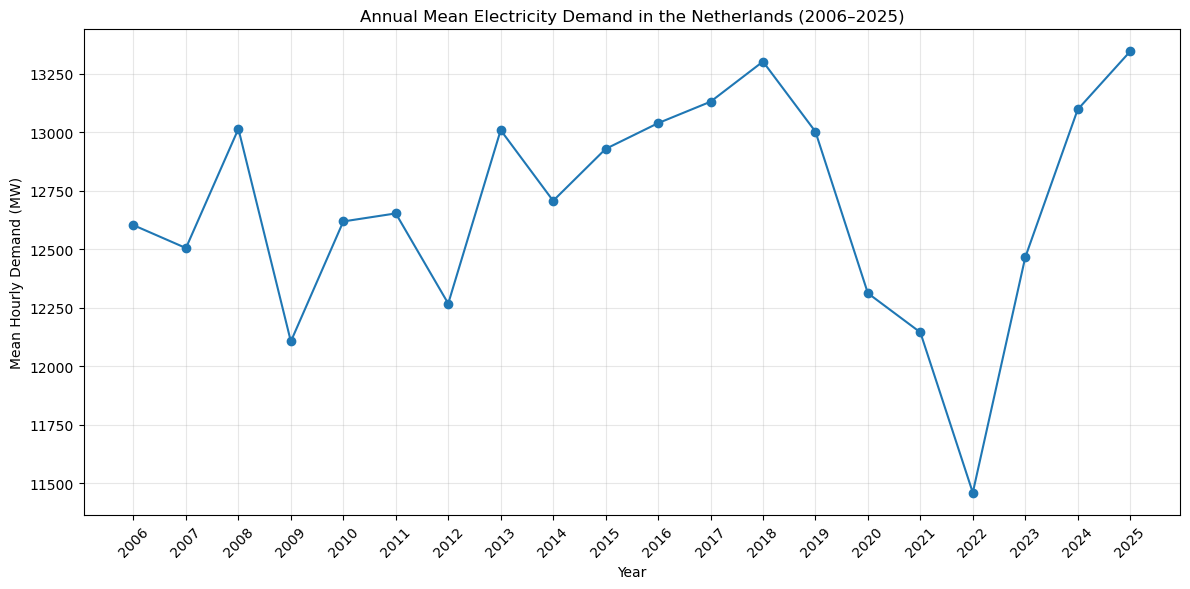

In [76]:
# Plot annual mean electricity demand from 2006 to 2025
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    annual_demand_summary["Year"],
    annual_demand_summary["Mean_Demand_MW"],
    marker="o"
)

plt.title("Annual Mean Electricity Demand in the Netherlands (2006–2025)")
plt.xlabel("Year")
plt.ylabel("Mean Hourly Demand (MW)")
plt.xticks(annual_demand_summary["Year"], rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Annual Comparison: Eurostat and ENTSO-E

Eurostat provides an annual electricity statistic, while ENTSO-E provides hourly system-load observations. For a broad comparison, the ENTSO-E hourly MW values are summed by year and converted to GWh. The measures have different definitions, so this comparison is intended to compare annual patterns—especially around 2022—not to prove that the values should be equal.

In [77]:
# Compare annual Eurostat electricity values with energy represented by ENTSO-E hourly load

entsoe_annual_gwh = (
    entsoe_nl_2006_2025.assign(Year=entsoe_nl_2006_2025["Timestamp"].dt.year)
    .groupby("Year")
    .agg(
        ENTSOE_Load_MWh=("Demand_MW", "sum"),
        Valid_Hours=("Demand_MW", "count"),
    )
    .reset_index()
)
entsoe_annual_gwh["ENTSOE_Load_GWh"] = entsoe_annual_gwh["ENTSOE_Load_MWh"] / 1000

annual_source_comparison = eurostat_annual[["Year", "Electricity_GWh"]].merge(
    entsoe_annual_gwh[["Year", "ENTSOE_Load_GWh", "Valid_Hours"]],
    on="Year",
    how="inner",
)

annual_source_comparison["Eurostat_Change_Percent"] = (
    annual_source_comparison["Electricity_GWh"].pct_change() * 100
)
annual_source_comparison["ENTSOE_Change_Percent"] = (
    annual_source_comparison["ENTSOE_Load_GWh"].pct_change() * 100
)

display(
    annual_source_comparison.loc[
        annual_source_comparison["Year"].between(2020, 2023),
        ["Year", "Electricity_GWh", "ENTSOE_Load_GWh", "Valid_Hours",
         "Eurostat_Change_Percent", "ENTSOE_Change_Percent"],
    ].round(2)
)


,Year,Electricity_GWh,ENTSOE_Load_GWh,Valid_Hours,Eurostat_Change_Percent,ENTSOE_Change_Percent
14,2020,112434.06,108147.19,8784,-1.08,-5.05
15,2021,113374.76,106386.69,8760,0.84,-1.63
16,2022,108062.28,100386.33,8760,-4.69,-5.64
17,2023,107041.00,109195.00,8760,-0.95,8.77


### 5.2 Annual Minimum and Maximum Electricity Demand

This section compares the minimum and maximum observed hourly electricity demand for each year from 2006 to 2025. The comparison will help illustrate how the range of observed demand varies over time, alongside the annual mean.

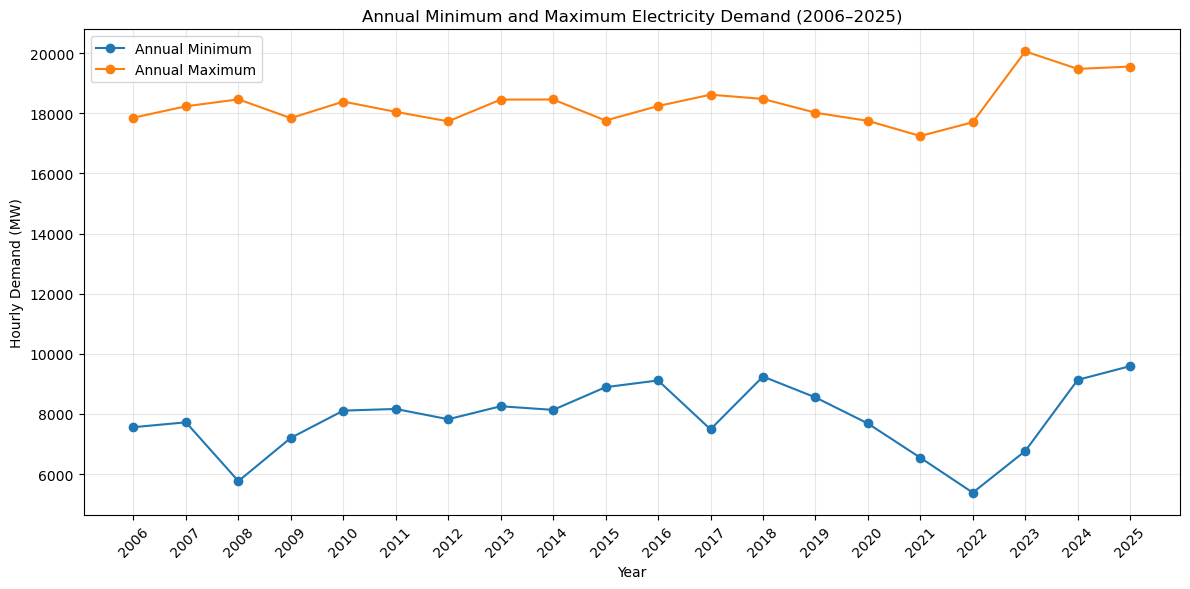

In [78]:
# Plot annual minimum and maximum electricity demand
plt.figure(figsize=(12, 6))

plt.plot(
    annual_demand_summary["Year"],
    annual_demand_summary["Minimum_Demand_MW"],
    marker="o",
    label="Annual Minimum"
)

plt.plot(
    annual_demand_summary["Year"],
    annual_demand_summary["Maximum_Demand_MW"],
    marker="o",
    label="Annual Maximum"
)

plt.title("Annual Minimum and Maximum Electricity Demand (2006–2025)")
plt.xlabel("Year")
plt.ylabel("Hourly Demand (MW)")
plt.xticks(annual_demand_summary["Year"], rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 5.3 Average Electricity Demand by Hour of Day

Hourly electricity demand can vary substantially throughout the day. This analysis calculates the average demand for each hour of the day across the full dataset, helping to identify typical daily demand patterns.

The 10 missing demand values will be excluded automatically from the relevant averages.

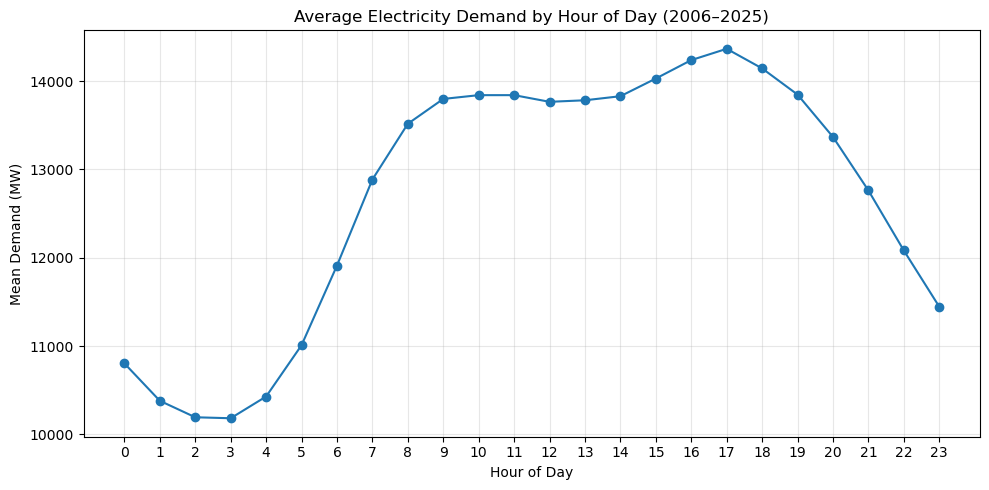

In [79]:
# Calculate average electricity demand for each hour of the day
entsoe_nl_2006_2025["Hour"] = (
    entsoe_nl_2006_2025["Timestamp"].dt.hour
)

hourly_demand_profile = (
    entsoe_nl_2006_2025
    .groupby("Hour")["Demand_MW"]
    .mean()
)

# Plot average demand by hour of day
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_demand_profile.index,
    hourly_demand_profile.values,
    marker="o"
)

plt.title("Average Electricity Demand by Hour of Day (2006–2025)")
plt.xlabel("Hour of Day")
plt.ylabel("Mean Demand (MW)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 5.4 Average Electricity Demand by Day of the Week

Electricity demand may vary depending on the day of the week because household, commercial, and industrial activity follows different weekly patterns.

This analysis calculates the average hourly demand for each day of the week across the available 2006–2025 observations. Days are displayed in calendar order, starting with Monday.

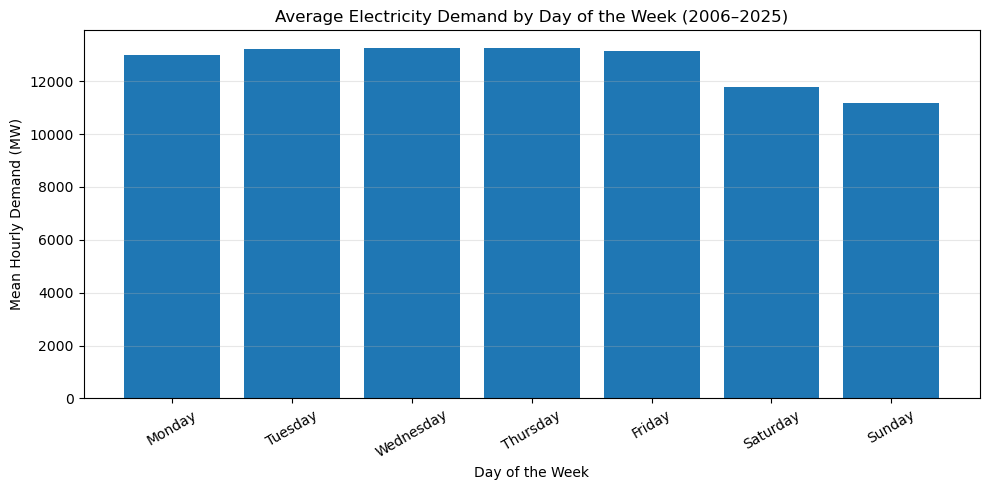

In [80]:
# Calculate average electricity demand by day of the week
entsoe_nl_2006_2025["DayOfWeek"] = (
    entsoe_nl_2006_2025["Timestamp"].dt.dayofweek
)

weekday_demand_profile = (
    entsoe_nl_2006_2025
    .groupby("DayOfWeek")["Demand_MW"]
    .mean()
)

# Label the days in calendar order
day_labels = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Plot average demand by day of the week
plt.figure(figsize=(10, 5))

plt.bar(
    day_labels,
    weekday_demand_profile.reindex(range(7)).values
)

plt.title("Average Electricity Demand by Day of the Week (2006–2025)")
plt.xlabel("Day of the Week")
plt.ylabel("Mean Hourly Demand (MW)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 5.5 Average Electricity Demand by Month

Electricity demand can vary across the year. This analysis calculates average hourly demand for each calendar month across the available 2006–2025 observations.

Comparing monthly averages will help identify seasonal patterns in Dutch electricity demand. Missing demand values will be excluded from the averages.

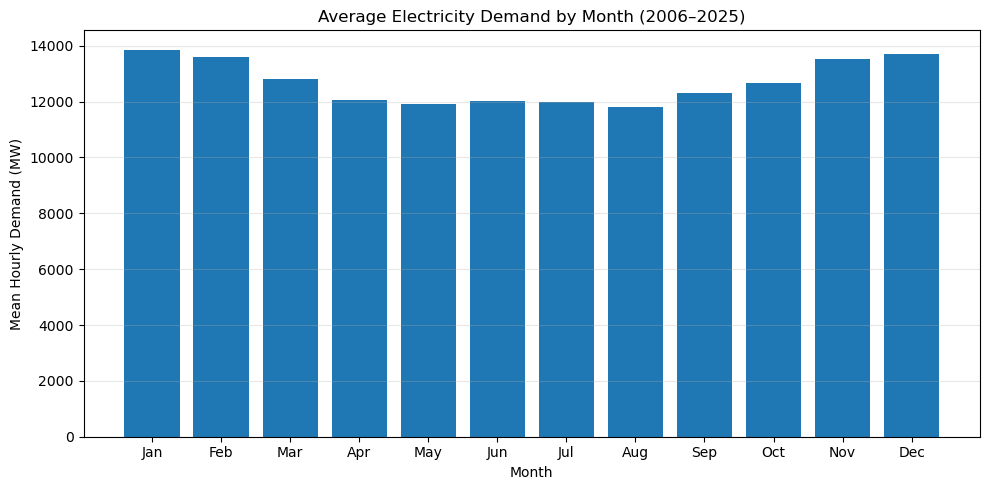

In [81]:
# Calculate average electricity demand by month
entsoe_nl_2006_2025["Month"] = (
    entsoe_nl_2006_2025["Timestamp"].dt.month
)

monthly_demand_profile = (
    entsoe_nl_2006_2025
    .groupby("Month")["Demand_MW"]
    .mean()
)

# Plot average demand by month
month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(10, 5))

plt.bar(
    month_labels,
    monthly_demand_profile.reindex(range(1, 13)).values
)

plt.title("Average Electricity Demand by Month (2006–2025)")
plt.xlabel("Month")
plt.ylabel("Mean Hourly Demand (MW)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 5.6 Summary of Exploratory Findings

The exploratory analysis of Dutch hourly electricity demand from 2006 to 2025 identified several descriptive patterns:

- **Long-term variation:** Annual mean demand fluctuated over the study period, declining notably from 2019 to 2022 before recovering through 2025.
- **Daily cycle:** Average demand was lowest overnight and increased through the morning, reaching an evening peak.
- **Weekly cycle:** Average demand was lower on Saturdays and Sundays than on weekdays.
- **Seasonality:** Average demand was higher in winter and lower during the summer months.

These findings describe patterns in the available data; they do not establish the causes of changes in electricity demand.

The combined dataset still contains 10 missing demand values associated with the March clock-change dates from 2006 to 2015. The older workbook's timezone convention also remains undocumented. These limitations must be addressed or explicitly accounted for before the dataset is finalized for forecasting.

## 6. Investigating the Electricity Load Dip in 2022

The Netherlands experienced a noticeable decline in average electricity load in 2022 compared with 2021. The purpose of this investigation is to explore possible factors that may help explain this change.

Rather than focusing only on solar power, this investigation considers the wider electricity system, including:

- **Electricity production:** renewable sources such as solar, wind, biomass and hydropower, as well as fossil fuels such as natural gas and coal.
- **Electricity imports and exports:** changes in how much electricity the Netherlands imported from or exported to other countries.
- **Electricity consumption:** changes in overall electricity use, where suitable data is available.
- **Energy prices:** whether the sharp rise in household energy prices around 2022 provides useful context for the observed change in electricity load.

The investigation will compare 2022 with 2021 and examine the years before and after 2022 where the available data allows.

The goal is to identify patterns and plausible explanations, not to assume that one factor caused the decline. Electricity production, international electricity trade, household energy prices and system-level electricity load measure different things, so their relationships must be interpreted carefully.

In [82]:
# Load the CBS electricity balance dataset
electricity_balance_df = pd.read_csv(
    raw_dir / "84575ENG_SelectieMetStatSymbol_20261013102003.csv",
    sep=";",
    dtype=str,
)

print("Electricity balance dataset shape:", electricity_balance_df.shape)
print("\nColumn names:")
print(electricity_balance_df.columns.tolist())

print("\nFirst five rows:")
display(electricity_balance_df.head())

Electricity balance dataset shape: (20, 31)

Column names:
['Periods', 'Gross production (mln kWh)', 'Own consumption for electr. production (mln kWh)', 'Net production/Net production, total (mln kWh)', 'Net production/Nuclear energy (mln kWh)', 'Net production/Fuels/Fuels, total (mln kWh)', 'Net production/Fuels/Coal (mln kWh)', 'Net production/Fuels/Petroleum products (mln kWh)', 'Net production/Fuels/Natural gas (mln kWh)', 'Net production/Fuels/Biomass (mln kWh)', 'Net production/Fuels/Other fuels (non-renewable) (mln kWh)', 'Net production/Hydro power (mln kWh)', 'Net production/Wind energy/Wind energy, total (mln kWh)', 'Net production/Wind energy/Wind energy on shore (mln kWh)', 'Net production/Wind energy/Wind energy off shore (mln kWh)', 'Net production/Solar photovoltaic (mln kWh)', 'Net production/Other sources (mln kWh)', 'Imports/Imports, total (mln kWh)', 'Imports/Belgium (mln kWh)', 'Imports/Denmark (mln kWh)', 'Imports/Germany (mln kWh)', 'Imports/United Kingdom (mln kW

,Periods,Gross production (mln kWh),Own consumption for electr. production (mln kWh),"Net production/Net production, total (mln kWh)",Net production/Nuclear energy (mln kWh),"Net production/Fuels/Fuels, total (mln kWh)",Net production/Fuels/Coal (mln kWh),Net production/Fuels/Petroleum products (mln kWh),Net production/Fuels/Natural gas (mln kWh),Net production/Fuels/Biomass (mln kWh),...,Imports/United Kingdom (mln kWh),Imports/Norway (mln kWh),"Exports/Exports, total (mln kWh)",Exports/Belgium (mln kWh),Exports/Denmark (mln kWh),Exports/Germany (mln kWh),Exports/United Kingdom (mln kWh),Exports/Norway (mln kWh),Distribution losses (mln kWh),Net consumption (calculated) (mln kWh)
0,2006,98835,3953,94882,.,.,.,.,.,4703,...,NaN,NaN,5887,5604,NaN,283,NaN,NaN,4537,111804
1,2007,105164,4120,101044,.,.,.,.,.,3556,...,NaN,NaN,5480,5231,NaN,249,NaN,NaN,4626,114027
2,2008,108201,4107,104094,.,.,.,.,.,4562,...,NaN,3155,9116,7957,NaN,827,NaN,333,4678,115266
3,2009,113503,4250,109253,.,.,.,.,.,5463,...,NaN,2813,10564,5792,NaN,3509,NaN,1263,4405,109736
4,2010,118150,3781,114369,.,.,.,.,.,6331,...,NaN,1327,12808,7390,NaN,3070,NaN,2347,4464,112681


In [83]:
# Convert the year column to numbers
electricity_balance_df["Periods"] = pd.to_numeric(
    electricity_balance_df["Periods"],
    errors="coerce"
)

# Inspect electricity balance data for 2019–2025
electricity_balance_recent = electricity_balance_df[
    electricity_balance_df["Periods"].between(2019, 2025)
]

columns_to_inspect = [
    "Periods",
    "Net production/Net production, total (mln kWh)",
    "Net production/Nuclear energy (mln kWh)",
    "Net production/Fuels/Natural gas (mln kWh)",
    "Net production/Fuels/Coal (mln kWh)",
    "Net production/Fuels/Biomass (mln kWh)",
    "Net production/Hydro power (mln kWh)",
    "Net production/Wind energy/Wind energy, total (mln kWh)",
    "Net production/Solar photovoltaic (mln kWh)",
    "Imports/Imports, total (mln kWh)",
    "Exports/Exports, total (mln kWh)",
    "Net consumption (calculated) (mln kWh)",
]

display(
    electricity_balance_recent[columns_to_inspect]
    .reset_index(drop=True)
)


,Periods,"Net production/Net production, total (mln kWh)",Net production/Nuclear energy (mln kWh),Net production/Fuels/Natural gas (mln kWh),Net production/Fuels/Coal (mln kWh),Net production/Fuels/Biomass (mln kWh),Net production/Hydro power (mln kWh),"Net production/Wind energy/Wind energy, total (mln kWh)",Net production/Solar photovoltaic (mln kWh),"Imports/Imports, total (mln kWh)","Exports/Exports, total (mln kWh)",Net consumption (calculated) (mln kWh)
0,2019.0,117862,3700,69407,19250,5067,74,11508,5399,20403,19548,113658
1,2020.0,119838,3865,71196,9601,7891,46,15278,8567,19773,22433,112434
2,2021.0,117919,3618,55520,16497,9817,88,17679,11304,20885,20632,113375
3,2022.0,117274,3930,46672,16481,8733,50,21071,16657,18544,22811,108139
4,2023.0,117830,3767,44976,10146,6771,69,29035,19607,19547,25206,107142


### Initial Observations: Electricity Balance in 2021–2022

The initial comparison of the Dutch electricity balance in 2021 and 2022 reveals several notable changes.

- **Lower net electricity consumption:** Net consumption decreased from 113,375 million kWh in 2021 to 108,139 million kWh in 2022, a decline of approximately 4.6%.

- **Reduced natural gas generation:** Electricity generation from natural gas decreased by approximately 15.9%, from 55,520 to 46,672 million kWh.

- **Increased renewable generation:** Wind generation increased by approximately 19.2%, while solar photovoltaic generation increased by approximately 47.4%.

- **Changes in international electricity trade:** Imports decreased by approximately 11.2%, while exports increased by approximately 10.6%.

- **Relatively stable total net production:** Despite these changes in the electricity mix, total net electricity production decreased by only approximately 0.5%.

These observations suggest that the decline in electricity consumption occurred alongside changes in electricity generation and international trade. The figures provide useful context for investigating the 2022 load dip, but they do not establish its cause.

The next step is to calculate year-on-year percentage changes across the surrounding years. This will help determine whether the changes observed in 2022 were unusual or part of longer-term trends.

In [84]:

# Calculate year-on-year percentage changes for key electricity measures

comparison_columns = {
    "Net consumption (calculated) (mln kWh)": "Net consumption",
    "Net production/Fuels/Natural gas (mln kWh)": "Natural gas generation",
    "Net production/Wind energy/Wind energy, total (mln kWh)": "Wind generation",
    "Net production/Solar photovoltaic (mln kWh)": "Solar generation",
    "Imports/Imports, total (mln kWh)": "Electricity imports",
    "Exports/Exports, total (mln kWh)": "Electricity exports",
}

annual_comparison = electricity_balance_df[
    ["Periods"] + list(comparison_columns.keys())
].copy()

# Convert years and measurements to numeric values
annual_comparison["Periods"] = pd.to_numeric(
    annual_comparison["Periods"], errors="coerce"
)

for column in comparison_columns:
    annual_comparison[column] = pd.to_numeric(
        annual_comparison[column], errors="coerce"
    )

# Remove rows without a valid year
annual_comparison = annual_comparison.dropna(subset=["Periods"])
annual_comparison = annual_comparison.sort_values("Periods")

# Calculate year-on-year percentage changes
annual_changes = (
    annual_comparison
    .set_index("Periods")[list(comparison_columns.keys())]
    .pct_change(fill_method=None)
    * 100
)

annual_changes = annual_changes.rename(columns=comparison_columns)

# Show the available years from 2019 to 2023
display(annual_changes.loc[2019:2023].round(1))


,Net consumption,Natural gas generation,Wind generation,Solar generation,Electricity imports,Electricity exports
Periods,,,,,,
2019.0,0.2,22.9,9.1,45.6,-23.7,4.1
2020.0,-1.1,2.6,32.8,58.7,-3.1,14.8
2021.0,0.8,-22.0,15.7,31.9,5.6,-8.0
2022.0,-4.6,-15.9,19.2,47.4,-11.2,10.6
2023.0,-0.9,-3.6,37.8,17.7,5.4,10.5


### Year-on-Year Changes: Key Findings

The year-on-year comparison highlights several changes in the Dutch electricity balance around 2022.

- **Net consumption decreased by 4.6% in 2022**, following a slight increase in 2021. It decreased by a further 0.9% in 2023.
- **Natural gas electricity generation decreased by 15.9% in 2022**, following a 22.0% decline in 2021.
- **Wind generation increased by 19.2% in 2022**, while solar photovoltaic generation increased by 47.4%.
- **Electricity imports decreased by 11.2%**, while exports increased by 10.6% in 2022.
- In 2023, wind and solar generation continued to increase, while net consumption decreased slightly.

These results show that the decline in electricity consumption coincided with substantial changes in the electricity generation mix and international electricity trade. However, these annual figures describe related trends rather than establish direct causes of the hourly electricity-load decline.

The next step is to investigate whether household energy prices also changed substantially around 2022, which may provide additional context for understanding the reduction in electricity consumption.

In [85]:
# Load the household energy-price dataset
energy_prices_file = raw_dir / "84672ENG_SelectieMetStatSymbol_20261019150733.csv"
energy_prices_df = pd.read_csv(energy_prices_file, sep=";")

print("Loaded household energy-price data from:", energy_prices_file)


Loaded household energy-price data from: ..\data\raw\84672ENG_SelectieMetStatSymbol_20261019150733.csv


In [86]:
# Inspect the household energy-price dataset

print("Dataset shape:", energy_prices_df.shape)

print("\nColumn names:")
print(energy_prices_df.columns.tolist())

print("\nFirst five rows:")
display(energy_prices_df.head())

Dataset shape: (57, 13)

Column names:
['VAT', 'Periods', 'Natural gas/Transport rate (Euro/year)', 'Natural gas/Fixed delivery rate (Euro/year)', 'Natural gas/Variable delivery rate (Euro/m3)', 'Natural gas/ODE tax (Environmental Taxes Act)  (Euro/m3)', 'Natural gas/Energy tax (Euro/m3)', 'Electricity/Transport rate (Euro/year)', 'Electricity/Fixed delivery rate (Euro/year)', 'Electricity/Variable delivery rate (Euro/kWh)', 'Electricity/ODE tax (Environmental Taxes Act) (Euro/kWh)', 'Electricity/Energy tax (Euro/kWh)', 'Electricity/Energy tax refund (Euro/year)']

First five rows:


,VAT,Periods,Natural gas/Transport rate (Euro/year),Natural gas/Fixed delivery rate (Euro/year),Natural gas/Variable delivery rate (Euro/m3),Natural gas/ODE tax (Environmental Taxes Act) (Euro/m3),Natural gas/Energy tax (Euro/m3),Electricity/Transport rate (Euro/year),Electricity/Fixed delivery rate (Euro/year),Electricity/Variable delivery rate (Euro/kWh),Electricity/ODE tax (Environmental Taxes Act) (Euro/kWh),Electricity/Energy tax (Euro/kWh),Electricity/Energy tax refund (Euro/year)
0,Including VAT,2019 January,177.92,59.89,0.3827,0.0634,0.35469,238.67,59.60,0.0865,0.02287,0.11934,-311.62
1,Including VAT,2019 February,177.58,66.12,0.3759,0.0634,0.35469,239.02,65.56,0.0857,0.02287,0.11934,-311.62
2,Including VAT,2019 March,177.58,66.12,0.3671,0.0634,0.35469,238.21,65.60,0.0841,0.02287,0.11934,-311.62
3,Including VAT,2019 April,177.58,66.12,0.3630,0.0634,0.35469,238.21,65.60,0.0820,0.02287,0.11934,-311.62
4,Including VAT,2019 May,177.58,66.12,0.3570,0.0634,0.35469,238.21,65.60,0.0811,0.02287,0.11934,-311.62


In [87]:
# Prepare monthly household energy prices for annual comparison

energy_prices_comparison = energy_prices_df[
    energy_prices_df["VAT"] == "Including VAT"
].copy()

# Extract the year from the monthly period, e.g. "2022 January"
energy_prices_comparison["Year"] = pd.to_numeric(
    energy_prices_comparison["Periods"].str[:4],
    errors="coerce"
)

# Convert the two variable-rate columns to numeric values
price_columns = [
    "Electricity/Variable delivery rate (Euro/kWh)",
    "Natural gas/Variable delivery rate (Euro/m3)",
]

for column in price_columns:
    energy_prices_comparison[column] = pd.to_numeric(
        energy_prices_comparison[column], errors="coerce"
    )

# Calculate annual averages
annual_energy_prices = (
    energy_prices_comparison
    .groupby("Year")[price_columns]
    .mean()
    .round(4)
)

display(annual_energy_prices)

,Electricity/Variable delivery rate (Euro/kWh),Natural gas/Variable delivery rate (Euro/m3)
Year,,
2019,0.0803,0.3505
2020,0.0707,0.2840
2021,0.1058,0.4150
2022,0.4581,1.7824
2023,NaN,NaN


In [88]:
# Check monthly household energy prices for 2022 and 2023

display(
    energy_prices_comparison.loc[
        energy_prices_comparison["Year"].isin([2022, 2023]),
        [
            "Periods",
            "Electricity/Variable delivery rate (Euro/kWh)",
            "Natural gas/Variable delivery rate (Euro/m3)",
        ],
    ].reset_index(drop=True)
)

,Periods,Electricity/Variable delivery rate (Euro/kWh),Natural gas/Variable delivery rate (Euro/m3)
0,2022 January,0.3169,1.1956
1,2022 February,0.2966,1.1247
2,2022 March,0.4814,1.8451
3,2022 April,0.4363,1.6844
4,2022 May,0.3613,1.4220
5,2022 June,0.3342,1.2181
6,2022 July,0.4187,1.5908
7,2022 August,0.5028,2.1147
8,2022 September,0.6439,2.7706
9,2022 October,0.6588,2.7830


### Household Electricity and Natural Gas Prices Around 2022

The annual averages show a substantial increase in household energy prices in the Netherlands in 2022 compared with 2021.

- **Electricity prices increased from €0.1058 to €0.4581 per kWh**, an increase of approximately 333%.
- **Natural gas prices increased from €0.4150 to €1.7824 per m³**, an increase of approximately 329%.
- Both variable delivery rates were therefore around 4.3 times their 2021 averages.

The monthly data shows that prices were particularly high in late summer and autumn 2022. Electricity reached €0.6588 per kWh in October, while natural gas reached €2.7830 per m³ in the same month.

These increases coincided with the decline in electricity use observed in 2022. Annual net consumption in the electricity-balance dataset decreased by 4.6% compared with 2021, while average hourly electricity load in the ENTSO-E dataset decreased by approximately 5.6%.

Higher household energy prices may have encouraged households to reduce their energy use, but these results alone cannot establish a causal relationship. Other factors may also have contributed to the decline.

The 2023 monthly price values shown in this dataset are missing, so the available results do not yet establish how household variable delivery rates changed after 2022.

**Conclusion:** The sharp rise in household electricity and natural gas rates provides relevant context for the reduction in electricity consumption observed in 2022. Further evidence would be needed to determine how much of the decline was associated with higher prices.

### Historical Context: The 2022 Energy Crisis

The decline in Dutch electricity load in 2022 coincided with major changes in the European energy market following Russia's invasion of Ukraine in February 2022.

According to Statistics Netherlands (CBS), renewable electricity production in the Netherlands increased by 20% in 2022, while production from fossil sources decreased by 11%. Natural gas-fired electricity production fell by 16%, partly because of high natural gas prices.

Electricity imports decreased by approximately 11%, while exports increased by approximately 11%. CBS identifies lower hydropower generation in Norway and lower nuclear electricity production in Germany as factors behind reduced imports. Lower French nuclear production also contributed to increased Dutch exports to neighbouring countries.

CBS separately reported that Dutch household natural gas consumption fell sharply in 2022. Warmer weather explained part of this decline, while higher gas prices were an important factor in the remaining reduction after adjusting for temperature.

Together, these findings provide context for the decline in electricity demand observed in this project. However, changes in electricity demand, electricity production, international electricity trade and household gas consumption measure different aspects of the energy system. The available evidence does not establish that the war or energy prices alone caused the observed electricity-load decline.

**Sources**

- CBS, [Renewable electricity share up by 20 percent in 2022](https://www.cbs.nl/en-gb/news/2023/10/renewable-electricity-share-up-by-20-percent-in-2022)
- CBS, [Natural gas consumption in 2022 at lowest level in 50 years](https://www.cbs.nl/en-gb/news/2023/07/natural-gas-consumption-in-2022-at-lowest-level-in-50-years)
- CBS, [Inflation rate 10.0 percent in 2022](https://www.cbs.nl/en-gb/news/2023/02/inflation-rate-10-0-percent-in-2022)

## 7. Final Data-Quality Audit

### 6.1 Validate the Combined Dataset

Before preparing the dataset for forecasting, we will perform a final quality check of the combined hourly electricity-demand records.

The audit will check:
- Total number of records and date range.
- Duplicate timestamps.
- Missing demand values.
- Timestamp intervals that differ from one hour.
- Whether demand values are numeric.

The results will help identify any remaining issues that need to be documented before the dataset is used for modelling.

In [89]:
# Perform a final data-quality audit

print("Total records:", len(entsoe_nl_2006_2025))
print("Start timestamp:", entsoe_nl_2006_2025["Timestamp"].min())
print("End timestamp:", entsoe_nl_2006_2025["Timestamp"].max())

print(
    "Duplicate timestamps:",
    entsoe_nl_2006_2025["Timestamp"].duplicated().sum()
)

print(
    "Missing demand values:",
    entsoe_nl_2006_2025["Demand_MW"].isna().sum()
)

print(
    "Non-numeric demand values:",
    pd.to_numeric(
        entsoe_nl_2006_2025["Demand_MW"],
        errors="coerce"
    ).isna().sum()
)

time_differences = (
    entsoe_nl_2006_2025["Timestamp"].diff().dropna()
)

print(
    "Intervals other than one hour:",
    (time_differences != pd.Timedelta(hours=1)).sum()
)

Total records: 175320
Start timestamp: 2006-01-01 00:00:00
End timestamp: 2025-12-31 23:00:00
Duplicate timestamps: 0
Missing demand values: 10
Non-numeric demand values: 10
Intervals other than one hour: 0


### 7.2 Final Data-Quality Audit: Findings

The combined dataset contains 175,320 records covering 1 January 2006 to 31 December 2025.

The audit identified:
- No duplicate timestamps.
- 10 missing demand values.
- No timestamp intervals other than one hour in the current timezone-naive representation.

The non-numeric demand check also returned 10 records because missing values are treated as non-numeric by the coercion used in the audit. No additional non-numeric demand values have been identified.

The 10 missing readings occur at 02:00 on March clock-change dates between 2006 and 2015. The original workbook does not document its timezone convention, so their interpretation remains uncertain.

The combined dataset is provisionally assembled, but the timezone limitation and missing demand values must be addressed or explicitly accounted for before final forecasting preparation.

## 8. Prepare and Export the Forecasting Dataset

The investigation and final quality audit are complete. This final step selects the timestamp and demand columns, validates the export, and saves the hourly dataset for the forecasting notebook.


In [90]:
# Prepare the final hourly dataset for forecasting
forecasting_input = (
    entsoe_nl_2006_2025[["Timestamp", "Demand_MW"]]
    .copy()
    .sort_values("Timestamp")
    .reset_index(drop=True)
)

# Validate the dataset before exporting
assert forecasting_input["Timestamp"].is_monotonic_increasing
assert forecasting_input["Timestamp"].is_unique
assert forecasting_input["Demand_MW"].notna().sum() == 175310

# Export the combined dataset, preserving missing demand values
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "entsoe_nl_hourly_2006_2025.csv"

forecasting_input.to_csv(output_file, index=False)

print("Export completed.")
print("File:", output_file.resolve())
print("Total records:", len(forecasting_input))
print("Missing demand values retained:", forecasting_input["Demand_MW"].isna().sum())
print("Start:", forecasting_input["Timestamp"].min())
print("End:", forecasting_input["Timestamp"].max())
print("Columns:", forecasting_input.columns.tolist())


Export completed.
File: C:\Users\Winifred\Ironhack\Part time program\Projects\Final project_v2\data\processed\entsoe_nl_hourly_2006_2025.csv
Total records: 175320
Missing demand values retained: 10
Start: 2006-01-01 00:00:00
End: 2025-12-31 23:00:00
Columns: ['Timestamp', 'Demand_MW']
